# Olist late-delivery prediction

**Goal.** Predict, at the moment an order is placed, whether it will be delivered *later than the estimated delivery date* shown to the customer. This is a binary classification problem where the positive class (late) is the minority.

**Label.** `late_delivery_flag = 1` if `delivered_date > order_estimated_delivery_date`, compared at day level, on delivered orders only.

**Ground rules I set for this project**
- Features may only use information available **at purchase time** (price, freight, product size/weight, category, customer and seller state, distance between them, the promised delivery window, purchase hour/day, and *past* history of sellers, zip codes, categories and the platform). Anything known only after the outcome (delivered date, carrier hand-off date, review score) is excluded.
- Joins and point-in-time history features are built in SQL (DuckDB); modelling is done in Python (scikit-learn, XGBoost).
- **Time-based** train/test split and time-ordered cross-validation (`TimeSeriesSplit`), never a random split.
- Metrics: PR-AUC (average precision) and precision/recall at a chosen threshold. Accuracy is not used because only a small share of orders are late.
- Be conservative: differences smaller than the fold-to-fold spread are treated as ties.

**Roadmap of this notebook**
1. Setup
2. Load the raw CSVs into DuckDB
3. Data audit (keys, grain, status, dates, join coverage)
4. Base table `features_base` (one row per order item)
5. Order-level feature table `order_features_v2` (point-in-time features in SQL)
6. Sanity checks (nulls, correlations, late rate by month)
7. Cleaning and derived columns
8. Time-based train/test split
9. Preprocessing, time-ordered CV and the Logistic Regression baseline
10. XGBoost and tuning
11. Logistic Regression vs XGBoost, fold by fold
12. Out-of-fold predictions and threshold choice
13. One evaluation on the test set
14. Why the model transfers poorly: SHAP shift
15. Does the recent platform late rate track the late rate? Monthly check
16. Ablation: do the platform features help?
17. Error analysis on the out-of-fold predictions (minimal version)
18. Conclusion, limitations and next steps

**Status / honesty note.** The numbers quoted in the markdown cells come from the outputs shown in this notebook; interpretations are marked as hypotheses, and where I could not confirm something from an output I say so. The test set was evaluated once (section 13) and then looked at again while diagnosing the drift (sections 14-15), so any change made *after* that point is post hoc and must be labelled as such when reporting results. Sections 16 and 17 use the training period only.

## 1. Setup

Imports for data handling (pandas, numpy), plotting (matplotlib, seaborn), preprocessing and modelling (scikit-learn, XGBoost), metrics, hyper-parameter distributions (scipy) and SHAP for model interpretation.

In [8]:
# Libraries: data (numpy, pandas), plots (matplotlib, seaborn), scikit-learn (preprocessing, CV, metrics),
# XGBoost, scipy distributions for the random search, and SHAP for interpretation.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

import xgboost as xgb
from xgboost import  XGBClassifier

from sklearn.metrics import confusion_matrix, classification_report, RocCurveDisplay, ConfusionMatrixDisplay,PrecisionRecallDisplay, precision_recall_curve, average_precision_score,precision_recall_curve

from scipy.stats import loguniform, randint, uniform,skew

from sklearn.base import clone
import shap

## 2. Load the raw CSVs into DuckDB

DuckDB runs SQL directly on local files, so the joins and the window-function features can be written in SQL without loading everything into pandas first. Each CSV becomes a table in the local file `olist.duckdb`.

- `read_csv_auto` infers column types.
- The two counts printed at the end are a quick load check: **99,441 orders** and **71 rows** in the category translation table.
- The paths are absolute paths on my machine; for the final repo they should become relative paths (e.g. `data/…`).

In [9]:
# One DuckDB table per CSV (read_csv_auto infers the column types). The paths are local to my machine;
# make them relative for the final repo. The last two lines print row counts as a load check.
import duckdb
con = duckdb.connect("olist.duckdb")

con.execute("""
CREATE OR REPLACE TABLE orders AS
SELECT * FROM read_csv_auto('..olist_orders_dataset.csv')
""")
con.execute("""
CREATE OR REPLACE TABLE order_items AS
SELECT * FROM read_csv_auto('..olist_order_items_dataset.csv')
""")
con.execute("""
CREATE OR REPLACE TABLE customers AS
SELECT * FROM read_csv_auto('..olist_customers_dataset.csv')
""")

con.execute("""
CREATE OR REPLACE TABLE sellers AS
SELECT * FROM read_csv_auto('..olist_sellers_dataset.csv')
""")

con.execute("""
CREATE OR REPLACE TABLE products AS
SELECT * FROM read_csv_auto('..olist_products_dataset.csv')
""")

con.execute("""
CREATE OR REPLACE TABLE geolocation AS
SELECT * FROM read_csv_auto('..olist_geolocation_dataset.csv')
""")

con.execute("""
CREATE OR REPLACE TABLE category_translation AS
SELECT * FROM read_csv_auto('..product_category_name_translation.csv')
""")


con.sql("SELECT COUNT(*) FROM orders").show()
con.sql("SELECT COUNT(*) FROM category_translation").show()

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│        99441 │
└──────────────┘

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│           71 │
└──────────────┘



## 3. Data audit

Before building anything I check what one row means in each table (grain), whether keys are unique, and how the tables join. The goal is to avoid silent row duplication or loss when I join.

### 3.1 Grain and keys of `orders`
`order_id` is unique in `orders` (the duplicate check returns nothing and the distinct count equals the row count, 99,441), so `orders` has one row per order.

In [10]:
# Peek at one order row to see the column formats.
con.sql("select * from orders limit 1").df()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18


In [11]:
# Uniqueness check: is any order_id repeated? (empty result = order_id is unique)
con.sql("select order_id,count(*) from orders group by 1 having count(*)>1").df()

,order_id,count_star()


In [12]:
# Number of distinct orders (equals the row count, so one row per order).
con.sql("select count(distinct order_id) from orders").df()

,count(DISTINCT order_id)
0,99441


### 3.2 Order status and date ranges
Only orders with status `delivered` have a delivered date, so the label can only be built for those (96,478 of 99,441 orders). The other statuses (shipped, canceled, unavailable, invoiced, processing, created, approved) are excluded from the modelling table.

The min/max query shows the purchase timestamps run from **2016-09-04 to 2018-10-17**, and delivered dates from 2016-10-11 to 2018-10-17. The very early months turn out to be nearly empty (see section 6.3), which matters for the history features and for the split.

In [13]:
# Orders per status. Only 'delivered' orders have a delivered date, so only they can be labelled.
con.sql("select distinct order_status, count(distinct order_id) from orders group by 1 order by 2 desc").df()

,order_status,count(DISTINCT order_id)
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [14]:
# Earliest and latest value of every date column: shows the time span and any odd dates.
con.sql("""select max(order_purchase_timestamp), min(order_purchase_timestamp), max(order_approved_at) ,min(order_approved_at) ,
max(order_delivered_carrier_date) ,min(order_delivered_carrier_date) , max(order_delivered_customer_date) ,min(order_delivered_customer_date) ,
max(order_estimated_delivery_date), min(order_estimated_delivery_date)

from orders""").df()

,max(order_purchase_timestamp),min(order_purchase_timestamp),max(order_approved_at),min(order_approved_at),max(order_delivered_carrier_date),min(order_delivered_carrier_date),max(order_delivered_customer_date),min(order_delivered_customer_date),max(order_estimated_delivery_date),min(order_estimated_delivery_date)
0,2018-10-17 17:30:18,2016-09-04 21:15:19,2018-09-03 17:40:06,2016-09-15 12:16:38,2018-09-11 19:48:28,2016-10-08 10:34:01,2018-10-17 13:22:46,2016-10-11 13:46:32,2018-11-12,2016-09-30


### 3.3 Order volume over time by status
A small loop builds one line chart per order status (orders per purchase month). This is only for visual inspection; it is not used by the model. Cells 7-8 just collect and print the list of statuses that the plot loop reuses.

In [15]:
# Scratch: collect the distinct statuses into a list. The name `list` shadows Python's built-in
# `list` for the rest of the session; consider renaming it.
list = con.sql("""select distinct order_status 
from orders
""").df()['order_status'].to_numpy().tolist()

In [16]:
# Scratch: print the statuses.
for n in list:
    print(n)

shipped
unavailable
approved
invoiced
processing
delivered
canceled
created


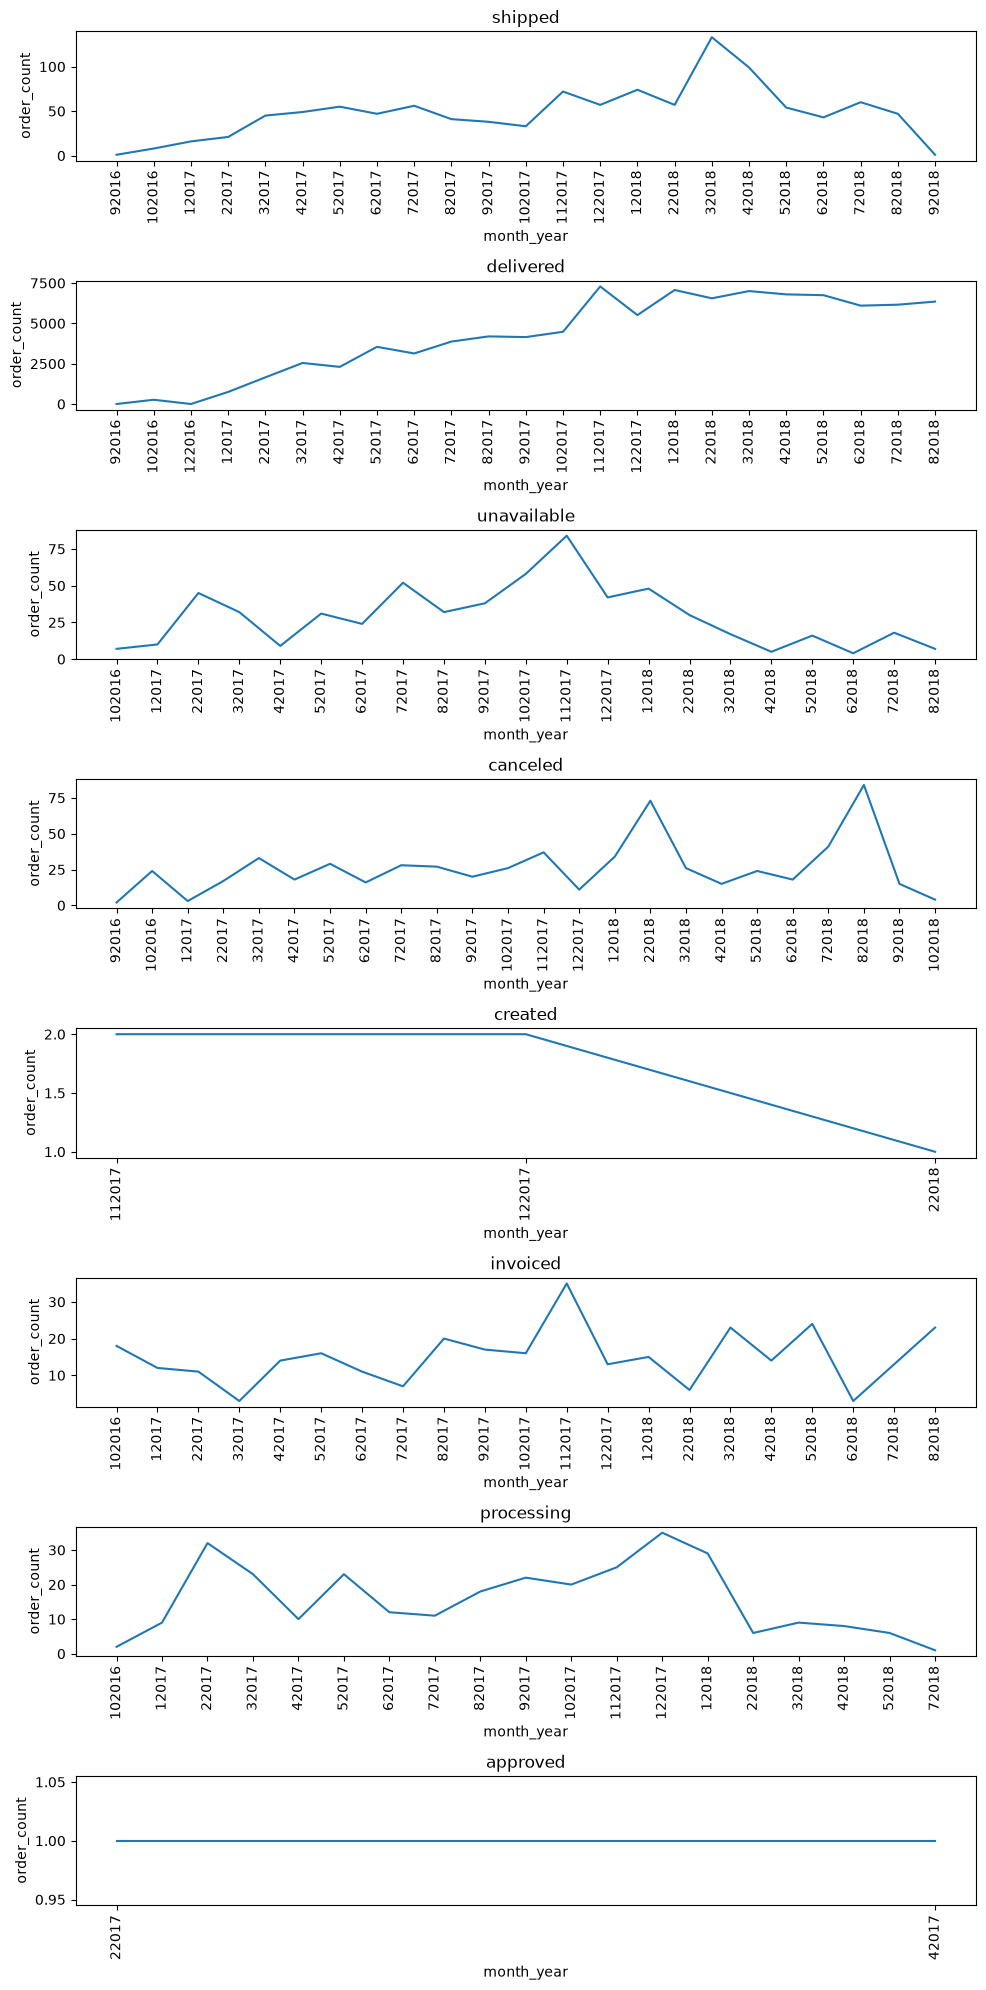

In [17]:
# One line chart per status: number of orders per purchase month (visual check only, not used by the model).
list = con.sql("""select distinct order_status 
from orders
""").df()['order_status'].to_numpy().tolist()

# one subplot per status (8 statuses)
fig, axes = plt.subplots(8,1,figsize=(10,20))
a = 0

for n in list:
    # orders per purchase month for this status; $x is bound from params
    df1 = con.sql("""select  month(order_purchase_timestamp) || year(order_purchase_timestamp) as month_year, month(order_purchase_timestamp) as month,
    year(order_purchase_timestamp) as year,
    count(distinct order_id) as order_count
    from orders
    where order_status = $x 
    group by 1,2,3
    order by 3,2 
    """, params={"x":n}).df()

    ax = axes[a]
    # one line per status
    sns.lineplot(data = df1, x= 'month_year', y = 'order_count', ax = ax)
    ax.set_title(n)
    ax.tick_params(axis="x", rotation=90)
    a+=1

plt.tight_layout();

### 3.4 Look at the other tables
One quick `limit 5` peek at each remaining table to see the columns and formats: `order_items` (price, freight, seller, product per item), `customers`, `sellers`, `products` (category, weight, dimensions), `geolocation` (many lat/lng points per zip prefix) and `category_translation`.

In [18]:
# Peek at order_items: one row per item with price, freight, seller and product.
con.sql("""select *
from order_items limit 5
""").df()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [19]:
# Peek at customers.
con.sql("""select *
from customers limit 5
""").df()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [20]:
# Peek at sellers.
con.sql("""select *
from sellers limit 5
""").df()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,04195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [21]:
# Peek at products (category, weight and dimensions).
con.sql("""select *
from products limit 5
""").df()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40,287,1,225,16,10,14
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44,276,1,1000,30,18,20
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46,250,1,154,18,9,15
3,cef67bcfe19066a932b7673e239eb23d,bebes,27,261,1,371,26,4,26
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37,402,4,625,20,17,13


In [22]:
# Peek at geolocation (several lat/lng points per zip prefix).
con.sql("""select *
from geolocation limit 5
""").df()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,01037,-23.545621,-46.639292,sao paulo,SP
1,01046,-23.546081,-46.644820,sao paulo,SP
2,01046,-23.546129,-46.642951,sao paulo,SP
3,01041,-23.544392,-46.639499,sao paulo,SP
4,01035,-23.541578,-46.641607,sao paulo,SP


In [23]:
# Peek at the category translation table.
con.sql("""select *
from category_translation limit 5
""").df()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


### 3.5 Category translation and join coverage
- The translation table has 71 categories, but `products` has 73 distinct category names, so two categories have no English translation. I therefore keep the original Portuguese `product_category_name` as the category feature and do not use the translation table in the final features.
- Every product in `order_items` exists in `products` (32,951 both sides).
- For **delivered** orders every join is complete: 96,478 orders all have items, a customer row, and (2,970 sellers, 32,216 products) match their dimension tables. So the joins do not lose delivered orders.

In [24]:
# Distinct categories in the translation table (Portuguese vs English).
con.sql("""select count(distinct product_category_name_english ), count(distinct product_category_name)
from category_translation 
""").df()

,count(DISTINCT product_category_name_english),count(DISTINCT product_category_name)
0,71,71


In [25]:
# Distinct categories in products: 73, versus 71 in the translation table (two have no translation).
con.sql("""select  count(distinct product_category_name)
from products
""").df()

,count(DISTINCT product_category_name)
0,73


In [26]:
# Do all products in order_items exist in products? (same count on both sides = yes)
con.sql("""select count(distinct a.product_id) as prod_count, count(distinct b.product_id) as pc2
from order_items a 
left join products b 
on a.product_id = b.product_id
""").df()

,prod_count,pc2
0,32951,32951


In [27]:
# Join coverage for delivered orders: the counts on both sides of every join match, so no delivered order is lost.
con.sql("""select count(distinct a.order_id) as order_count, count(distinct b.order_id) as item_table_order_count, 
count(distinct a.customer_id) as order_cust_count, count(distinct c.customer_id) as cust_table_cust_count,
count(distinct b.seller_id) as item_table_seller_count,count(distinct s.seller_id) as seller_table_seller_count,
count(distinct b.product_id) as item_table_product_count,count(distinct p.product_id) as product_table_product_count

from orders a 
left join order_items b 
on a.order_id = b.order_id

left join customers c 
on a.customer_id = c.customer_id

left join sellers s 
on b.seller_id = s.seller_id

left join products p 
on p.product_id = b.product_id

where a.order_status = 'delivered'

""").df()

,order_count,item_table_order_count,order_cust_count,cust_table_cust_count,item_table_seller_count,seller_table_seller_count,item_table_product_count,product_table_product_count
0,96478,96478,96478,96478,2970,2970,32216,32216


### 3.6 Grain of `order_items`
- 98,666 orders have at least one item (the remaining orders of the 99,441 have no item rows).
- `(order_id, order_item_id)` is unique (no duplicates), and there are 112,650 item rows in total.
- So an order can have several items, and the modelling table (one row per order) must **aggregate** the items. That is done in section 5.

In [28]:
# Distribution of items per order; the sum is the number of orders that have at least one item.
con.sql("""
select sum(order_count) from 
(select item_count, count(distinct order_id) as order_count from
(select order_id, count(distinct order_item_id) as item_count
from order_items
group by 1 
)
group by 1
order by 1 asc)
""").df()

,sum(order_count)
0,98666.0


In [29]:
# Is (order_id, order_item_id) unique? (empty result = yes)
con.sql("""
select order_id,order_item_id, count( order_item_id) as item_count
from order_items
group by 1,2 
having  count( order_item_id) > 1
""").df()

,order_id,order_item_id,item_count


In [30]:
# Total number of item rows.
con.sql("""select count(order_item_id) from order_items""").df()

,count(order_item_id)
0,112650


## 4. Base table `features_base` (one row per order item)

This joins orders, items, customers, sellers, products and geolocation, keeping only delivered orders that have both a delivered date and an estimated delivery date.

- **Geolocation:** the raw table has many lat/lng points for the same zip prefix (e.g. 94 different latitudes for prefix 68180). I take the **median** lat/lng per prefix (`geolocationv2`) so each zip prefix maps to one point, for both seller and buyer.
- `delivered_date` is the delivered timestamp cast to a date, so lateness is compared at day level.
- Result: **110,189 item rows** (printed count).

In [31]:
# features_base: item-level table joining orders, items, customers, sellers, products and the median
# coordinates per zip prefix. Restricted to delivered orders with a delivered date and an estimated date.
con.sql(""" create or replace table features_base as 
with geolocationv2 as 
(
select geolocation_zip_code_prefix, MEDIAN(geolocation_lat) as geolocation_lat, MEDIAN(geolocation_lng) as geolocation_lng from geolocation
group by 1 
)

select a.order_id,a.customer_id, a.order_purchase_timestamp, date(a.order_delivered_customer_date) as delivered_date, a.order_estimated_delivery_date,
b.order_item_id, b.product_id, b.seller_id,b.price, b.freight_value,c.customer_unique_id,customer_zip_code_prefix, c.customer_city, c.customer_state,
s.seller_zip_code_prefix, s.seller_city, s.seller_state, p.product_category_name,
p.product_weight_g, p.product_length_cm, p.product_height_cm, p.product_width_cm,
g1.geolocation_lat as seller_lat, g1.geolocation_lng as seller_lng,
g2.geolocation_lat as buyer_lat, g2.geolocation_lng as buyer_lng
 
from orders a 
left join order_items b 
on a.order_id = b.order_id

left join customers c 
on a.customer_id = c.customer_id

left join sellers s 
on b.seller_id = s.seller_id

left join products p 
on p.product_id = b.product_id

left join geolocationv2 g1 
on s.seller_zip_code_prefix = g1.geolocation_zip_code_prefix

left join geolocationv2 g2 
on c.customer_zip_code_prefix = g2.geolocation_zip_code_prefix

where a.order_status = 'delivered' and a.order_delivered_customer_date is not null and a.order_estimated_delivery_date is not null
""")

CountBIGINT
110189


### 4.1 Quick checks on `features_base`
- 4,981 orders have the seller and the customer in the same city.
- No item has `price = 0`, so the `freight / price` ratio later is safe (the SQL still guards against zero).

In [32]:
# Orders where the seller and the customer are in the same city.
con.sql("""select  count(distinct order_id)
from features_base
where seller_city = customer_city
""").df() 

,count(DISTINCT order_id)
0,4981


In [33]:
# Any item with price 0? (empty = none; relevant for the freight / price ratio)
con.sql("""select  *
from features_base
where price = 0 
""").df() 

,order_id,customer_id,order_purchase_timestamp,delivered_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,price,freight_value,...,seller_state,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,seller_lat,seller_lng,buyer_lat,buyer_lng


### 4.2 Further checks that shaped the feature design (and old drafts)
These cells are exploration. The live checks show:
- 2,997 `customer_unique_id`s map to more than one `customer_id` (in this dataset a `customer_id` is generated per order, so a returning customer gets a new id) and 250 have more than one zip prefix. Repeat customers are a small share of customers, so I did not build customer-level history; I used **zip-code-level** history instead.
- 4,119 distinct customer cities, which is too many to one-hot, so I use state and zip-level information instead of city.
- Zip prefixes with several coordinates (hence the median).
- The last live query lists the number of sellers per order. In my earlier check 1,278 orders had more than one seller; I assign such an order to its **primary seller**, the seller of the highest-priced item.

The commented-out blocks are older drafts that were replaced by the full query in section 5 (kept for reference only).

In [34]:
# OLD DRAFT (commented out): an earlier version of the order-level query, replaced by order_features_v2
# (section 5). Kept for reference only.
# con.sql("""select order_id,order_purchase_timestamp, count(distinct order_item_id) as item_count, 
# count(distinct seller_id) as seller_count, 
# sum(price) as total_price, sum(freight_value) as total_freight, case when  sum(price) >0 then sum(freight_value)/ sum(price) else 0 end as freight_ratio,
# sum(product_weight_g) as total_weight, max(product_weight_g) as max_weight, 
# max(product_length_cm) as max_length, max(product_height_cm) as max_height, max(product_width_cm) as max_width, 
# avg(product_length_cm) as avg_length, avg(product_height_cm) as avg_height, avg(product_width_cm) as avg_width, 
# sum(product_length_cm*product_height_cm*product_width_cm) as total_volume, max(product_length_cm*product_height_cm*product_width_cm) as max_volume,
# count(distinct product_category_name_english) as category_count, mode(product_category_name_english) as max_category,

# case when delivered_date > order_estimated_delivery_date then 1 else 0 end as late_delivery_flag
# ,datediff('day',date(order_purchase_timestamp), order_estimated_delivery_date) as eta_days,seller_state,customer_state,
# case when seller_state = customer_state then 1 else 0 end as same_state_flag, hour(order_purchase_timestamp) as order_hour, day(order_purchase_timestamp) as order_day, 


# haversine_km(seller_lat, seller_lng, buyer_lat, buyer_lng) AS distance_km, 
# count(distinct order_id) over(partition by seller_id order by order_purchase_timestamp asc rows between unbounded preceding and 1 preceding ) as seller_past_orders,
# count(distinct case when delivered_date > order_estimated_delivery_date then order_id end) 
# over(partition by seller_id order by order_purchase_timestamp asc rows between unbounded preceding and 1 preceding ) as seller_past_delays,
# avg(datediff('day',date(order_purchase_timestamp), order_estimated_delivery_date)) over(partition by seller_id  order by order_purchase_timestamp asc rows between unbounded preceding and 1 preceding ) as seller_avg_eta,

# COUNT(DISTINCT order_id) OVER (
#     PARTITION BY seller_id
#     ORDER BY CAST(order_purchase_timestamp AS DATE)
#     RANGE BETWEEN INTERVAL '7 days' PRECEDING AND INTERVAL '1 day' preceding
# ) AS seller_7d_rolling_orders,

# COUNT(DISTINCT order_id) OVER (
#     ORDER BY CAST(order_purchase_timestamp AS DATE)
#     RANGE BETWEEN INTERVAL '7 days' PRECEDING AND INTERVAL '1 day' preceding
# ) AS platform_7d_rolling_orders,


# count(distinct order_id) over(partition by customer_zip_code_prefix order by order_purchase_timestamp asc rows between unbounded preceding and 1 preceding ) as cust_code_past_orders,
# count(distinct case when delivered_date > order_estimated_delivery_date then order_id end) 
# over(partition by customer_zip_code_prefix order by order_purchase_timestamp asc rows between unbounded preceding and 1 preceding ) as cust_code_past_delays,

# count(distinct order_id) over(partition by product_category_name_english  order by order_purchase_timestamp asc rows between unbounded preceding and 1 preceding ) as category_past_orders,
# count(distinct case when delivered_date > order_estimated_delivery_date then product_category_name_english end) 
# over(partition by cproduct_category_name_english  order by order_purchase_timestamp asc rows between unbounded preceding and 1 preceding ) as category_past_delays

# from features_base
# limit 10
# """).df()

In [35]:
# customer_unique_id with more than one customer_id: customer_id is generated per order,
# customer_unique_id identifies a person.
con.sql("""select  customer_unique_id, count(distinct customer_id) as map_count
from customers
group by 1 
having count(distinct customer_id) > 1
""").df()

,customer_unique_id,map_count
0,031e19fc630c4121f1238716f41675c3,2
1,a53b3da0cf3e158e78cad26c27a06d19,2
2,85b33fdcff5e20584ac9ec8e3c559ea3,2
3,35c62cb24d4c38a9d121fed1a43b2237,2
4,d74572d564d4ddc3cf3d286fdb4145eb,2
...,...,...
2992,1f90117a847636892e3c5bf569f2ac68,2
2993,8d6512fa0e1c5cdbd789b956de79fe2f,2
2994,4666e7be827bb14bf746a56f740e62c5,2
2995,14d46ad43ae7e3cd6944258b9840373b,2


In [37]:
# Customers that appear with more than one zip prefix.
con.sql("""select  customer_unique_id, count(distinct customer_zip_code_prefix	) as map_count
from customers
group by 1 
having count(distinct customer_zip_code_prefix	) > 1
""").df()

,customer_unique_id,map_count
0,313febe2adc914a7cb3f6e903f8e13cf,2
1,ce41a50f9ff95ef577cb759483fe9165,2
2,b495d807ccbd38ea1be486a826c88008,2
3,ae0ef1d2e3a62b54a83dadad4db14f5d,2
4,c9b3b24308b1a4587ffa3e60fafc2b1f,2
...,...,...
245,597e54e653cbc1ce5df1e6d97bbc448c,2
246,d4a5e9f19897de65433c9d97bf4b9f8e,2
247,012452d40dafae4df401bced74cdb490,2
248,2c6a91479a7dc00d8c9d650d8dee88ca,2


In [38]:
# Number of distinct customer cities (too many to one-hot encode).
con.sql("""select count(distinct customer_city)
from customers
""").df()

,count(DISTINCT customer_city)
0,4119


In [39]:
# Zip prefixes with several distinct latitudes in geolocation (why the median per prefix is used).
con.sql("""select geolocation_zip_code_prefix, count(distinct geolocation_lat)
from geolocation group by 1 
having count(distinct geolocation_lat)>1
limit 5
""").df()

,geolocation_zip_code_prefix,count(DISTINCT geolocation_lat)
0,66625,23
1,66815,13
2,67118,11
3,68030,56
4,68220,45


In [41]:
# Number of distinct sellers per order. The 'having' filter is commented out, so every order is listed;
# orders with more than one seller are assigned to their primary seller in order_features_v2.
con.sql("""select order_id, count(distinct seller_id) as seller_count from order_items
group by 1 
--having count(distinct seller_id) > 1
""").df()

,order_id,seller_count
0,008c3a655c66f4d92370d0d422732f69,1
1,0436c197b0ba8265af9fa94b7f444866,1
2,065ac4b340bafd4f6bee041c63e10aef,1
3,0758015124a0c9af755d31a7bf0efedc,3
4,0fa0372b06bb8a9e774500bd29dab06e,1
...,...,...
98661,ec4d827c7096de48c5a84a438bcd8922,1
98662,f3d73893c5b2bd8aed47d188dd5484ae,1
98663,f4cae1cef6439e6a8f3cdd16dff3d6a9,1
98664,f8f1e1019197846c66b6467545bcc6b5,1


## 5. Order-level feature table `order_features_v2`

This single SQL statement turns `features_base` (item level) into **one row per delivered order** with the label and all purchase-time features. The Python variable `K_PRIOR` (20) sets the strength of the shrinkage described below; it is an assumption and was not tuned.

### How the query is organised (CTE by CTE)
1. **`order_agg`**: collapses items to orders. Counts (`item_count`, `seller_count`, `product_count`), sums (`total_price`, `total_freight`, weights, volume), maxima/averages of product dimensions, `freight_ratio`, the *primary seller* and `top_category` (both taken from the highest-priced item with `ARG_MAX`), the label `late_delivery_flag`, the promised window `eta_days` (purchase date to estimated delivery date, known at purchase), `same_state_flag`, purchase hour and day of week, `distance_km`, `distance_per_day` and a missing-location flag.
2. **`order_with_history`**: window functions with `ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING`, ordered by purchase time with `order_id` as tie-break, so each order only sees *earlier* orders of the same seller, customer zip and category (`seller_past_orders`, `cust_code_past_orders`, `category_past_orders`, `seller_avg_eta`). `seller_7d_rolling_orders` and `platform_7d_rolling_orders` count orders over the previous 7 days up to *yesterday* (the current day is excluded).
3. **`seller_cum`, `zip_cum`, `cat_cum`, `state_cum`, `platform_cum`**: cumulative counts of delivered orders and late orders per entity **by delivery date**. An order's outcome is only known on the day it is delivered, so history has to be indexed by delivery date, not purchase date. This is what prevents label leakage.
4. **`joined`**: five `ASOF LEFT JOIN`s attach to every order the latest cumulative row whose `delivered_date` is **strictly before** the order's purchase date (`b.order_date > x.delivered_date`). Missing history becomes 0 counts via `COALESCE`.
5. **`rates` and the final `SELECT`**: shrunken late rates `(late + K * parent_rate) / (n + K)`. With few past orders the rate is pulled toward the parent rate; with many it approaches the entity's own rate. The hierarchy is zip -> state -> platform, seller -> platform, category -> platform (columns `*_hist_late_rate`).
6. **`daily` + correlated sub-queries**: trailing 14-day and 7-day platform delivery counts and late rates (`platform_delivered_14d/7d`, `platform_late_rate_14d/7d`) using only deliveries on days strictly before the order date.

### Why shrinkage
A seller with 2 past orders of which 1 was late has a raw rate of 50%, which is mostly noise. Shrinking toward the parent rate keeps small-sample entities close to the average and lets well-observed entities speak for themselves.

### Things to know
- History is built only from delivered orders (the base table is filtered to delivered), so counts such as `seller_past_orders` count earlier *delivered* orders.
- The label and delivered date columns are in this table for splitting and evaluation only. They are removed from the features in section 8.
- Output: **96,470 rows x 58 columns**, `order_id` unique (confirmed in section 6). That is 8 fewer than the 96,478 delivered orders in `orders`; presumably they lack a delivered or estimated date (the filter in `features_base`), but I did not verify this in the notebook.
- `month` is `YYYYMM` of the purchase. It is used for diagnostics and filtering only and is **not** a model feature (it is in `drop_cols`).

#### Reference: the `haversine_km` macro used above
The distance feature calls a DuckDB macro that is **not created by any cell in this notebook**. It was defined earlier in `olist.duckdb` (DuckDB persists macros in the database file), so a fresh database would fail at the next cell. Its definition is recorded here for reproducibility:

```sql
CREATE OR REPLACE MACRO haversine_km(lat1, lng1, lat2, lng2) AS (
    CASE WHEN lat1 IS NULL OR lng1 IS NULL OR lat2 IS NULL OR lng2 IS NULL THEN NULL
    ELSE 2 * 6371.0 * ASIN(LEAST(1.0, SQRT(
            POWER(SIN(RADIANS(lat2 - lat1) / 2), 2) +
            COS(RADIANS(lat1)) * COS(RADIANS(lat2)) *
            POWER(SIN(RADIANS(lng2 - lng1) / 2), 2)))) END
);
```

The `CASE WHEN ... IS NULL THEN NULL` guard matters: without it `LEAST` ignores NULLs and orders with missing coordinates got a bogus distance of about 20,015 km.

In [42]:
# Build order_features_v2 in SQL (see the markdown above for the CTE-by-CTE explanation), then read it
# back into pandas in time order. K_PRIOR is the shrinkage strength: how many 'pseudo-orders' of the
# parent rate are mixed into each historical rate.
K_PRIOR = 20   # shrinkage strength (an assumption; compare 10/20/50 by CV)

con.execute(f"""
CREATE OR REPLACE TABLE order_features_v2 AS
-- Step 1 (order_agg): collapse item rows to one row per order (grain = order_id and month).
WITH order_agg AS (
    SELECT
        order_id,
        YEAR(order_purchase_timestamp) * 100 + MONTH(order_purchase_timestamp) as month,
        -- primary seller, its location and state = those of the highest-priced item; MAX() picks one value for order-level attributes
        ARG_MAX(seller_id, price) AS primary_seller_id,
        MAX(customer_zip_code_prefix) AS customer_zip_code_prefix,
        MAX(order_purchase_timestamp) AS order_purchase_timestamp,
        CAST(MAX(order_purchase_timestamp) AS DATE) AS order_date,
        MAX(delivered_date) AS delivered_date,
        MAX(order_estimated_delivery_date) AS order_estimated_delivery_date,
        ARG_MAX(seller_state, price) AS primary_seller_state,
        MAX(customer_state) AS customer_state,
        ARG_MAX(seller_lat, price) AS seller_lat,
        ARG_MAX(seller_lng, price) AS seller_lng,
        MAX(buyer_lat) AS buyer_lat,
        MAX(buyer_lng) AS buyer_lng,
        -- basket size: items, sellers and distinct products
        1 AS order_count,
        COUNT(DISTINCT order_item_id) AS item_count,
        COUNT(DISTINCT seller_id) AS seller_count,
        COUNT(DISTINCT product_id) AS product_count,
        SUM(price) AS total_price,
        SUM(freight_value) AS total_freight,
        -- freight as a share of price (0 when the price is 0)
        CASE WHEN SUM(price) > 0 THEN SUM(freight_value) / SUM(price) ELSE 0 END AS freight_ratio,
        -- product size features: totals, maxima and averages over the items
        SUM(product_weight_g) AS total_weight,
        MAX(product_weight_g) AS max_weight,
        MAX(product_length_cm) AS max_length,
        MAX(product_height_cm) AS max_height,
        MAX(product_width_cm) AS max_width,
        AVG(product_length_cm) AS avg_length,
        AVG(product_height_cm) AS avg_height,
        AVG(product_width_cm) AS avg_width,
        SUM(product_length_cm * product_height_cm * product_width_cm) AS total_volume,
        MAX(product_length_cm * product_height_cm * product_width_cm) AS max_volume,
        COUNT(DISTINCT product_category_name) AS category_count,
        -- category of the highest-priced item, unknown when missing
        COALESCE(ARG_MAX(product_category_name, price), 'unknown') AS top_category,
        -- LABEL: 1 if delivered after the estimated date (an outcome, never a feature)
        CASE WHEN MAX(delivered_date) > MAX(order_estimated_delivery_date) THEN 1 ELSE 0 END AS late_delivery_flag,
        -- promised window in days (known at purchase time)
        DATEDIFF('day', CAST(MAX(order_purchase_timestamp) AS DATE), MAX(order_estimated_delivery_date)) AS eta_days,
        CASE WHEN ARG_MAX(seller_state, price) = MAX(customer_state) THEN 1 ELSE 0 END AS same_state_flag,
        HOUR(MAX(order_purchase_timestamp)) AS order_hour,
        DAYOFWEEK(MAX(order_purchase_timestamp)) AS order_day_of_week,
        -- seller-to-buyer distance in km (NULL if any coordinate is missing)
        haversine_km(
            ARG_MAX(seller_lat, price), ARG_MAX(seller_lng, price),
            MAX(buyer_lat), MAX(buyer_lng)
        ) AS distance_km,
        -- distance divided by the promised days
        case when DATEDIFF('day', CAST(MAX(order_purchase_timestamp) AS DATE), MAX(order_estimated_delivery_date)) > 0 then
        haversine_km(
            ARG_MAX(seller_lat, price), ARG_MAX(seller_lng, price),
            MAX(buyer_lat), MAX(buyer_lng)
        ) / DATEDIFF('day', CAST(MAX(order_purchase_timestamp) AS DATE), MAX(order_estimated_delivery_date))

        else haversine_km(
            ARG_MAX(seller_lat, price), ARG_MAX(seller_lng, price),
            MAX(buyer_lat), MAX(buyer_lng)
        ) end as distance_per_day,
        -- 1 if any of the four coordinates is missing
        max(case when seller_lat is null or seller_lng is null or buyer_lat is null or buyer_lng is null then 1 else 0 end) as seller_or_buyer_loc_missing

    FROM features_base
    GROUP BY 1,2
),
-- Step 2 (order_with_history): history from EARLIER orders only. 1 PRECEDING excludes the current row,
-- and the 7-day windows end yesterday.
order_with_history AS (
    SELECT
        *,
        COALESCE(SUM(order_count) OVER (
            PARTITION BY primary_seller_id
            ORDER BY order_purchase_timestamp, order_id
            ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING), 0) AS seller_past_orders,
        AVG(eta_days) OVER (
            PARTITION BY primary_seller_id
            ORDER BY order_purchase_timestamp, order_id
            ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS seller_avg_eta,
        COALESCE(SUM(order_count) OVER (
            PARTITION BY primary_seller_id
            ORDER BY order_date
            RANGE BETWEEN INTERVAL '7 days' PRECEDING AND INTERVAL '1 day' PRECEDING), 0) AS seller_7d_rolling_orders,
        COALESCE(SUM(order_count) OVER (
            ORDER BY order_date
            RANGE BETWEEN INTERVAL '7 days' PRECEDING AND INTERVAL '1 day' PRECEDING), 0) AS platform_7d_rolling_orders,
        COALESCE(SUM(order_count) OVER (
            PARTITION BY customer_zip_code_prefix
            ORDER BY order_purchase_timestamp, order_id
            ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING), 0) AS cust_code_past_orders,
        COALESCE(SUM(order_count) OVER (
            PARTITION BY top_category
            ORDER BY order_purchase_timestamp, order_id
            ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING), 0) AS category_past_orders
    FROM order_agg
),
-- Step 3 (*_cum): cumulative delivered and late counts per entity, indexed by DELIVERY date,
-- because an outcome is only known on the day the order is delivered.
seller_cum AS (
    SELECT k, delivered_date,
           SUM(n)      OVER (PARTITION BY k ORDER BY delivered_date) AS cum_n,
           SUM(n_late) OVER (PARTITION BY k ORDER BY delivered_date) AS cum_late
    FROM (SELECT primary_seller_id AS k, delivered_date,
                 COUNT(*) AS n, SUM(late_delivery_flag) AS n_late
          FROM order_agg GROUP BY 1, 2)
),
zip_cum AS (
    SELECT k, delivered_date,
           SUM(n)      OVER (PARTITION BY k ORDER BY delivered_date) AS cum_n,
           SUM(n_late) OVER (PARTITION BY k ORDER BY delivered_date) AS cum_late
    FROM (SELECT customer_zip_code_prefix AS k, delivered_date,
                 COUNT(*) AS n, SUM(late_delivery_flag) AS n_late
          FROM order_agg GROUP BY 1, 2)
),
cat_cum AS (
    SELECT k, delivered_date,
           SUM(n)      OVER (PARTITION BY k ORDER BY delivered_date) AS cum_n,
           SUM(n_late) OVER (PARTITION BY k ORDER BY delivered_date) AS cum_late
    FROM (SELECT top_category AS k, delivered_date,
                 COUNT(*) AS n, SUM(late_delivery_flag) AS n_late
          FROM order_agg GROUP BY 1, 2)
),
state_cum AS (
    SELECT k, delivered_date,
           SUM(n)      OVER (PARTITION BY k ORDER BY delivered_date) AS cum_n,
           SUM(n_late) OVER (PARTITION BY k ORDER BY delivered_date) AS cum_late
    FROM (SELECT customer_state AS k, delivered_date,
                 COUNT(*) AS n, SUM(late_delivery_flag) AS n_late
          FROM order_agg GROUP BY 1, 2)
),
-- platform-wide version: constant key 1 so all orders share one series
platform_cum AS (
    SELECT 1 AS k, delivered_date,
           SUM(n)      OVER (ORDER BY delivered_date) AS cum_n,
           SUM(n_late) OVER (ORDER BY delivered_date) AS cum_late
    FROM (SELECT delivered_date, COUNT(*) AS n, SUM(late_delivery_flag) AS n_late
          FROM order_agg GROUP BY 1)
),
-- Step 4 (daily): delivered and late orders per delivery day, used for the trailing 7/14-day platform features.
daily AS (   -- deliveries and late deliveries per delivery day, for the recent platform late rate
    SELECT delivered_date AS d, COUNT(*) AS n, SUM(late_delivery_flag) AS n_late
    FROM order_agg
    GROUP BY 1
),
-- Step 5 (joined): ASOF join = latest cumulative row strictly BEFORE the order date,
-- so no same-day or future outcome leaks in. Missing history becomes 0.
joined AS (
    SELECT
        b.*,
        COALESCE(s.cum_n, 0)     AS seller_hist_delivered,
        COALESCE(s.cum_late, 0)  AS s_late,
        COALESCE(z.cum_n, 0)     AS zip_hist_delivered,
        COALESCE(z.cum_late, 0)  AS z_late,
        COALESCE(c.cum_n, 0)     AS cat_hist_delivered,
        COALESCE(c.cum_late, 0)  AS c_late,
        COALESCE(st.cum_n, 0)    AS st_n,
        COALESCE(st.cum_late, 0) AS st_late,
        COALESCE(p.cum_n, 0)     AS p_n,
        COALESCE(p.cum_late, 0)  AS p_late
    FROM (SELECT *, 1 AS plat_k FROM order_with_history) b
    ASOF LEFT JOIN seller_cum   s  ON b.primary_seller_id = s.k        AND b.order_date > s.delivered_date
    ASOF LEFT JOIN zip_cum      z  ON b.customer_zip_code_prefix = z.k AND b.order_date > z.delivered_date
    ASOF LEFT JOIN cat_cum      c  ON b.top_category = c.k             AND b.order_date > c.delivered_date
    ASOF LEFT JOIN state_cum    st ON b.customer_state = st.k          AND b.order_date > st.delivered_date
    ASOF LEFT JOIN platform_cum p  ON b.plat_k = p.k                   AND b.order_date > p.delivered_date
),
-- Step 6 (rates): platform rate, and the state rate shrunk toward the platform rate.
rates AS (
    SELECT *,
        p_late * 1.0 / NULLIF(p_n, 0) AS platform_rate,
        (st_late + {K_PRIOR} * (p_late * 1.0 / NULLIF(p_n, 0))) / (st_n + {K_PRIOR}) AS state_hist_late_rate
    FROM joined
)
SELECT
    -- Step 7 (final select): drop helper columns and shrink each rate: (late + K * parent rate) / (n + K), with K = K_PRIOR.
    -- Parents: seller and category -> platform, zip -> state, state -> platform.
    * EXCLUDE (plat_k, s_late, z_late, c_late, st_n, st_late, p_n, p_late, platform_rate),
    (s_late + {K_PRIOR} * platform_rate)         / (seller_hist_delivered + {K_PRIOR}) AS seller_hist_late_rate,
    (z_late + {K_PRIOR} * state_hist_late_rate)  / (zip_hist_delivered + {K_PRIOR})    AS zip_hist_late_rate,
    (c_late + {K_PRIOR} * platform_rate)         / (cat_hist_delivered + {K_PRIOR})    AS cat_hist_late_rate,

    -- recent platform late rate: only orders delivered on days strictly before this order's date
    (SELECT COALESCE(SUM(n), 0) FROM daily
      WHERE d BETWEEN r.order_date - 14 AND r.order_date - 1) AS platform_delivered_14d,
    (SELECT SUM(n_late) * 1.0 / NULLIF(SUM(n), 0) FROM daily
      WHERE d BETWEEN r.order_date - 14 AND r.order_date - 1) AS platform_late_rate_14d,
    (SELECT COALESCE(SUM(n), 0) FROM daily
      WHERE d BETWEEN r.order_date - 7 AND r.order_date - 1)  AS platform_delivered_7d,
    (SELECT SUM(n_late) * 1.0 / NULLIF(SUM(n), 0) FROM daily
      WHERE d BETWEEN r.order_date - 7 AND r.order_date - 1)  AS platform_late_rate_7d
FROM rates r
""")

# read the table back into pandas in time order (the split below relies on this order)
df_order_features = con.sql(
    "SELECT * FROM order_features_v2 ORDER BY order_purchase_timestamp, order_id"
).df()
df_order_features.shape

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(96470, 58)

## 6. Sanity checks on the feature table

Read the table back and check it before modelling. The first cell shows the first rows.

In [43]:
# First rows of the feature table.
df_order_features.head()

,order_id,month,primary_seller_id,customer_zip_code_prefix,order_purchase_timestamp,order_date,delivered_date,order_estimated_delivery_date,primary_seller_state,customer_state,...,zip_hist_delivered,cat_hist_delivered,state_hist_late_rate,seller_hist_late_rate,zip_hist_late_rate,cat_hist_late_rate,platform_delivered_14d,platform_late_rate_14d,platform_delivered_7d,platform_late_rate_7d
0,bfbd0f9bdef84302105ad712db648a6c,201609,ecccfa2bb93b34a3bf033cc5d1dcdc69,14600,2016-09-15 12:16:38,2016-09-15,2016-11-09,2016-10-04,PR,SP,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,3b697a20d9e427646d92567910af6d57,201610,522620dcb18a6b31cd7bdf73665113a9,04106,2016-10-03 09:44:50,2016-10-03,2016-10-26,2016-10-27,PR,SP,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,be5bc2f0da14d8071e2d45451ad119d9,201610,f09b760d23495ac9a7e00d29b769007c,98280,2016-10-03 16:56:50,2016-10-03,2016-10-27,2016-11-07,SP,RS,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,a41c8759fbe7aab36ea07e038b2d4465,201610,45d33f715e24d15a6ccf5c17b3a23e3c,90040,2016-10-03 21:13:36,2016-10-03,2016-11-03,2016-11-29,SP,RS,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
4,d207cc272675637bfed0062edffd0818,201610,cca3071e3e9bb7d12640c9fbe2301306,13185,2016-10-03 22:06:03,2016-10-03,2016-10-31,2016-11-23,SP,SP,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN


### 6.1 Missing values
Columns with missing values (96,470 rows at this point):
- Seller coordinates 213, buyer coordinates 264, which gives **476** missing `distance_km` / `distance_per_day`.
- 16 rows without product weight/dimensions (a few products have no size information).
- `seller_avg_eta`: 2,959 (sellers with no earlier order, i.e. no history).
- `*_hist_late_rate` and `platform_late_rate_14d`: 266, and `platform_late_rate_7d`: 332. These are the first days of the dataset when no order had been delivered yet. Section 7 drops those early rows (after that only 65 rows still have a missing 7-day rate).

How missing values are handled later: median imputation plus a missing-indicator for Logistic Regression; XGBoost handles NaN natively.

In [46]:
# Missing values per column (interpretation in the markdown above).
df_order_features.isna().sum()

order_id                            0
month                               0
primary_seller_id                   0
customer_zip_code_prefix            0
order_purchase_timestamp            0
order_date                          0
delivered_date                      0
order_estimated_delivery_date       0
primary_seller_state                0
customer_state                      0
seller_lat                        213
seller_lng                        213
buyer_lat                         264
buyer_lng                         264
order_count                         0
item_count                          0
seller_count                        0
product_count                       0
total_price                         0
total_freight                       0
freight_ratio                       0
total_weight                       16
max_weight                         16
max_length                         16
max_height                         16
max_width                          16
avg_length  

In [47]:
# Rows and unique orders: one row per order (both 96,470).
df_order_features.shape, df_order_features["order_id"].nunique()

((96470, 58), 96470)

### 6.2 Correlation of each numeric column with the label
All correlations are weak: the strongest are `platform_7d_rolling_orders` (+0.115), `distance_per_day` (+0.106), `zip_hist_late_rate` (+0.087) and `same_state_flag` (-0.068). A linear correlation is only a rough screen (it misses non-linear and interaction effects), but weak values like these also suggest that predictive power will be modest. These were computed before the 2016 rows were dropped and before any log transform.

In [48]:
# Correlation of each numeric column with the label. [:-2] drops the last two sorted entries
# (the label's correlation with itself and a constant column).
df_order_features.corr(numeric_only = True)['late_delivery_flag'].sort_values()[:-2]

same_state_flag               -0.067617
eta_days                      -0.033311
seller_avg_eta                -0.029837
seller_count                  -0.025987
product_count                 -0.021865
item_count                    -0.015251
category_count                -0.012248
platform_late_rate_14d        -0.003730
order_day_of_week             -0.002569
seller_lng                     0.000240
platform_late_rate_7d          0.002346
cat_hist_late_rate             0.003819
seller_or_buyer_loc_missing    0.006736
order_hour                     0.007177
max_width                      0.007419
freight_ratio                  0.008720
avg_width                      0.009089
seller_hist_delivered          0.013918
max_height                     0.014276
zip_hist_delivered             0.014652
total_volume                   0.015179
avg_height                     0.015831
max_length                     0.017224
seller_past_orders             0.017670
total_price                    0.017859


### 6.3 Volume and late rate by purchase month
- Months before 2017 have almost no data (1, 265 and 1 orders), so their late rates are meaningless (e.g. 100% from a single order).
- From 2017-01 on, volume grows from 750 to about 6,000-7,000 orders per month. 2017-11 jumps to 7,288 from 4,478 the month before.
- The late rate is **not stable**: about 3% in calm months, but 12.4% in 2017-11, 14.1% in 2018-02 and 19.0% in 2018-03, then down to 1.2% in 2018-06. The 2017-11 spike comes with a volume surge; the 2018-02 and 2018-03 spikes do not (volume was flat), so volume alone does not explain them, and I cannot tell the cause from this data.
- This non-stationarity is the central difficulty of the project and shows up again in the test results.

In [49]:
# Orders per purchase month.
df_order_features.groupby('month')["order_count"].sum()

month
201609       1
201610     265
201612       1
201701     750
201702    1653
201703    2546
201704    2303
201705    3545
201706    3135
201707    3872
201708    4193
201709    4150
201710    4478
201711    7288
201712    5513
201801    7069
201802    6555
201803    7003
201804    6798
201805    6749
201806    6096
201807    6156
201808    6351
Name: order_count, dtype: int32

In [50]:
# Late rate (%) per purchase month. The first months have only 1-265 orders, so their rates are meaningless.
100 *df_order_features.groupby('month')['late_delivery_flag'].sum() / df_order_features.groupby('month')["order_count"].sum()

month
201609    100.000000
201610      0.754717
201612      0.000000
201701      2.933333
201702      2.964307
201703      4.556167
201704      6.556665
201705      2.990127
201706      3.030303
201707      2.789256
201708      2.909611
201709      4.385542
201710      4.175971
201711     12.403952
201712      7.455106
201801      5.700948
201802     14.126621
201803     18.963301
201804      4.501324
201805      6.563935
201806      1.164698
201807      3.378817
201808      6.188002
dtype: float64

### 6.4 Zoom in on the spike months
Daily late rate (by purchase date) for 2017-11, 2018-02 and 2018-03. The plot shows the daily rate over the whole period. The days above 10% fall between 2017-11-14 and 2017-11-29 and between 2018-02-08 and 2018-03-15. Across the 89 days of the three spike months the mean daily late rate is 14.1% (min 2.2%, max 30.2%).

I considered removing these spike periods but did not: they are real events and the model would then never see them, so I keep them and treat the instability as a feature of the data (and a limitation).

In [51]:
# Subset with the three spike months (2017-11, 2018-02, 2018-03).
df2 = df_order_features[df_order_features['month'].isin([201711, 201802, 201803])]

In [52]:
# Confirm the months in the subset.
df2["month"].unique()

array([201711, 201802, 201803])

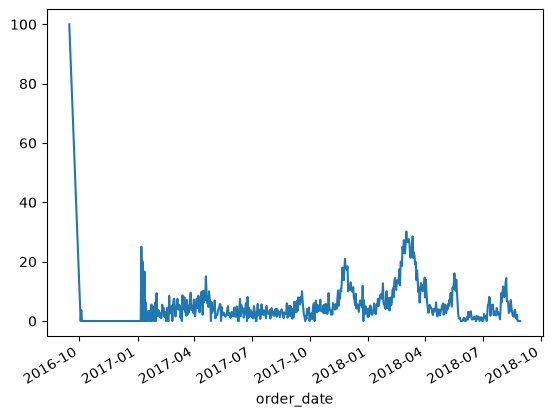

In [53]:
# Plot the daily late rate (%) over the whole period, then compute the daily late rate for the spike months (df3).
(100 *df_order_features.groupby('order_date')['late_delivery_flag'].sum() / df_order_features.groupby('order_date')["order_count"].sum()).plot()

df3 = pd.DataFrame(
    data=100 * df2.groupby("order_date")["late_delivery_flag"].sum()
         / df2.groupby("order_date")["order_count"].sum(),
    columns=["late_delivery_pct"]
)

In [54]:
# Days in the spike months where the daily late rate is above 10%.
df3[df3['late_delivery_pct']>10]

,late_delivery_pct
order_date,
2017-11-14,10.326087
2017-11-18,10.638298
2017-11-19,10.191083
2017-11-20,13.242009
2017-11-21,18.018018
2017-11-22,14.736842
2017-11-23,13.805970
2017-11-24,17.349608
2017-11-25,20.944559


In [55]:
# Daily late rate of the spike months as a Series (used for the summary below).
df3 = 100* df2.groupby('order_date')['late_delivery_flag'].sum() / df2.groupby('order_date')["order_count"].sum()

In [56]:
# Summary statistics of the daily late rate in the spike months.
df3.describe()

count    89.000000
mean     14.083022
std       7.550563
min       2.173913
25%       7.762557
50%      13.242009
75%      19.886364
max      30.152672
dtype: float64

In [58]:
# First rows again (same table as before).
df_order_features.head()

,order_id,month,primary_seller_id,customer_zip_code_prefix,order_purchase_timestamp,order_date,delivered_date,order_estimated_delivery_date,primary_seller_state,customer_state,...,zip_hist_delivered,cat_hist_delivered,state_hist_late_rate,seller_hist_late_rate,zip_hist_late_rate,cat_hist_late_rate,platform_delivered_14d,platform_late_rate_14d,platform_delivered_7d,platform_late_rate_7d
0,bfbd0f9bdef84302105ad712db648a6c,201609,ecccfa2bb93b34a3bf033cc5d1dcdc69,14600,2016-09-15 12:16:38,2016-09-15,2016-11-09,2016-10-04,PR,SP,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,3b697a20d9e427646d92567910af6d57,201610,522620dcb18a6b31cd7bdf73665113a9,04106,2016-10-03 09:44:50,2016-10-03,2016-10-26,2016-10-27,PR,SP,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,be5bc2f0da14d8071e2d45451ad119d9,201610,f09b760d23495ac9a7e00d29b769007c,98280,2016-10-03 16:56:50,2016-10-03,2016-10-27,2016-11-07,SP,RS,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,a41c8759fbe7aab36ea07e038b2d4465,201610,45d33f715e24d15a6ccf5c17b3a23e3c,90040,2016-10-03 21:13:36,2016-10-03,2016-11-03,2016-11-29,SP,RS,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
4,d207cc272675637bfed0062edffd0818,201610,cca3071e3e9bb7d12640c9fbe2301306,13185,2016-10-03 22:06:03,2016-10-03,2016-10-31,2016-11-23,SP,SP,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN


## 7. Cleaning and small derived columns

- **Drop purchases before 2017-01** (267 rows). Those months have almost no orders and no history; dropping them also removes the missing history rates seen above (96,203 rows remain).
- `distance_unknown`: 1 when the distance could not be computed (missing coordinates).
- `new_seller`: 1 when the seller has no earlier order.
- The next cells list columns/dtypes and show `item_count` (90% of orders have a single item: 86,598 of 96,203).
- `distance_unknown` and `seller_or_buyer_loc_missing` are close to duplicates (their skewness is almost identical), so one of them is probably redundant.

In [59]:
# Keep purchases from 2017-01 onward (drops 267 almost-empty early rows).
df_order_features = df_order_features[~(df_order_features['month'] < 201701)]

In [60]:
# Missing values after dropping the early rows.
df_order_features.isnull().sum()

order_id                            0
month                               0
primary_seller_id                   0
customer_zip_code_prefix            0
order_purchase_timestamp            0
order_date                          0
delivered_date                      0
order_estimated_delivery_date       0
primary_seller_state                0
customer_state                      0
seller_lat                        213
seller_lng                        213
buyer_lat                         264
buyer_lng                         264
order_count                         0
item_count                          0
seller_count                        0
product_count                       0
total_price                         0
total_freight                       0
freight_ratio                       0
total_weight                       16
max_weight                         16
max_length                         16
max_height                         16
max_width                          16
avg_length  

In [61]:
# Flag: the distance could not be computed (missing coordinates).
df_order_features['distance_unknown'] = np.where(df_order_features['distance_km'].isnull(), 1,0)

In [62]:
# Flag: the seller has no earlier order (no history).
df_order_features['new_seller'] = np.where(df_order_features['seller_past_orders']==0, 1,0)

In [63]:
# Sorted list of columns.
df_order_features.columns.sort_values()

Index(['avg_height', 'avg_length', 'avg_width', 'buyer_lat', 'buyer_lng',
       'cat_hist_delivered', 'cat_hist_late_rate', 'category_count',
       'category_past_orders', 'cust_code_past_orders', 'customer_state',
       'customer_zip_code_prefix', 'delivered_date', 'distance_km',
       'distance_per_day', 'distance_unknown', 'eta_days', 'freight_ratio',
       'item_count', 'late_delivery_flag', 'max_height', 'max_length',
       'max_volume', 'max_weight', 'max_width', 'month', 'new_seller',
       'order_count', 'order_date', 'order_day_of_week',
       'order_estimated_delivery_date', 'order_hour', 'order_id',
       'order_purchase_timestamp', 'platform_7d_rolling_orders',
       'platform_delivered_14d', 'platform_delivered_7d',
       'platform_late_rate_14d', 'platform_late_rate_7d', 'primary_seller_id',
       'primary_seller_state', 'product_count', 'same_state_flag',
       'seller_7d_rolling_orders', 'seller_avg_eta', 'seller_count',
       'seller_hist_delivered', 'sel

In [64]:
# Column types and non-null counts (96,203 rows, 60 columns).
df_order_features.info()

<class 'pandas.DataFrame'>
RangeIndex: 96203 entries, 267 to 96469
Data columns (total 60 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96203 non-null  str           
 1   month                          96203 non-null  int64         
 2   primary_seller_id              96203 non-null  str           
 3   customer_zip_code_prefix       96203 non-null  str           
 4   order_purchase_timestamp       96203 non-null  datetime64[us]
 5   order_date                     96203 non-null  datetime64[us]
 6   delivered_date                 96203 non-null  datetime64[us]
 7   order_estimated_delivery_date  96203 non-null  datetime64[us]
 8   primary_seller_state           96203 non-null  str           
 9   customer_state                 96203 non-null  str           
 10  seller_lat                     95990 non-null  float64       
 11  seller_lng              

In [65]:
# Distribution of item_count (about 90% of orders have a single item).
df_order_features['item_count'].value_counts().sort_index(ascending=False).head(50)

item_count
21        1
20        2
15        2
14        2
13        1
12        5
11        4
10        8
9         3
8         8
7        22
6       189
5       192
4       493
3      1301
2      7372
1     86598
Name: count, dtype: int64

### 7.1 Skewed columns and `log1p`
The skewness table highlights heavily right-skewed columns (e.g. `total_freight` 12.3, `total_price` 9.9, `freight_ratio` 9.7, counts of items/products). I apply `np.log1p` to ten of them (`skew_cols`) so Logistic Regression is not dominated by extreme values.

- `log1p` is a fixed function with no parameters learned from data, so applying it to the whole table before the split does **not** leak information.
- Tree models (XGBoost) are unaffected by monotone transforms, so this only helps the linear model.
- **Warning:** the cell overwrites the columns in place, so running it twice applies `log1p` twice. Re-run the cells above first if you need to repeat it.

In [66]:
# Skewness of every numeric column (large positive = long right tail). The RuntimeWarning comes from
# near-constant columns.
numeric_cols = df_order_features.select_dtypes(include="number").columns
skews = df_order_features[numeric_cols].apply(skew).sort_values(key=abs, ascending=False)
print(skews)

C:\Users\saiar\anaconda3\Lib\site-packages\pandas\core\apply.py:1183: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  results[i] = self.func(v, *self.args, **self.kwargs)


distance_unknown               14.110709
seller_or_buyer_loc_missing    14.050905
total_freight                  12.292114
total_price                     9.897655
seller_count                    9.870313
freight_ratio                   9.681566
product_count                   8.053748
item_count                      7.569385
new_seller                      5.568869
seller_7d_rolling_orders        3.933112
late_delivery_flag              3.435556
zip_hist_delivered              3.386019
cust_code_past_orders           3.367781
seller_hist_delivered           2.671716
seller_past_orders              2.553487
zip_hist_late_rate              1.947567
seller_hist_late_rate           1.795528
state_hist_late_rate            1.697748
category_count                 -1.507673
platform_late_rate_14d          1.211372
cat_hist_delivered              1.007323
category_past_orders            0.953660
eta_days                        0.828073
order_hour                     -0.601760
same_state_flag 

In [67]:
# WARNING: this overwrites the columns in place. Run it only once per fresh load of the table,
# otherwise log1p is applied twice.
skew_cols = ['total_freight','total_price', 'freight_ratio', 'product_count', 'item_count','seller_7d_rolling_orders','zip_hist_delivered','cust_code_past_orders'
            ,'seller_hist_delivered','seller_past_orders']

for c in skew_cols:
    df_order_features[c] = np.log1p(df_order_features[c])

## 8. Time-based train/test split

- `window` is the 95th percentile of the delivery time (delivered date minus purchase date). It is used as a **gap**: an order bought just before the cutoff may still be undelivered at the cutoff, so its label would not have been known. The gap keeps the training labels honest.
- `cutoff` is the 80th percentile of purchase time; orders at or after it form the **test** set (the most recent period). `train_end = cutoff - window`; the training set ends there. Orders between `train_end` and `cutoff` are dropped (6,629 rows by my arithmetic: 96,203 - 70,332 - 19,242).
- Result: **70,332 train rows (late rate 7.67%)** and **19,242 test rows (late rate 3.50%)**. The late rate halves from train to test, which is already a warning sign for the transfer of the model.
- `drop_cols` removes identifiers, timestamps and the label, plus `month` (a time index that would let a model memorise periods). Everything left, 51 columns, is a candidate feature.

In [68]:
# 95th percentile of the purchase-to-delivery time; used as the gap between train and test.
# (The value is not printed in this notebook.)
window = (df_order_features['delivered_date'] - df_order_features['order_date']).quantile(0.95)

In [69]:
# Time-based split: train = older orders, test = newest orders, with a gap in between.
# Last 20% of orders (by purchase time) as test, rest as train
# cutoff = 80th percentile of purchase time; later orders form the test set
cutoff    = df_order_features["order_purchase_timestamp"].quantile(0.80)    # test starts here (an assumption)
# stop the training period one `window` before the cutoff so training labels were already known at the cutoff
train_end = cutoff - window

# train = purchased before train_end; test = purchased on or after cutoff. Orders in between are dropped (the gap).
train = df_order_features[df_order_features["order_purchase_timestamp"] <  train_end]
test  = df_order_features[df_order_features["order_purchase_timestamp"] >= cutoff]

# sizes and late rates: train rows, test rows, train late rate, test late rate
print(len(train), len(test), train["late_delivery_flag"].mean(), test["late_delivery_flag"].mean())


70332 19242 0.07669339703122334 0.03497557426462946


In [70]:
# Features X and label y. Drop identifiers, timestamps, the label itself and `month` from X.
drop_cols = ["order_id", "primary_seller_id", "customer_zip_code_prefix",
             "order_purchase_timestamp", "order_date", "delivered_date",
             "order_estimated_delivery_date", "late_delivery_flag","month"]
# X = features only, y = the label
X_train, y_train = train.drop(columns=drop_cols), train["late_delivery_flag"]
X_test,  y_test  = test.drop(columns=drop_cols),  test["late_delivery_flag"]

## 9. Feature lists, preprocessing and the Logistic Regression baseline

- `cat_cols`: the 3 categorical columns (`primary_seller_state`, `customer_state`, `top_category`). `num_cols`: the other 48.
- `order_count` is constant (always 1), so it carries no information (its LR coefficient is exactly 0 below). It could be dropped.

### Preprocessing for Logistic Regression (`lr_pipe`)
- **Numeric:** `SimpleImputer(strategy="median", add_indicator=True)` fills missing values with the *training* median and adds a 0/1 flag where the value was missing, then `StandardScaler` puts features on the same scale (needed for regularised LR).
- **Categorical:** `OneHotEncoder` with `min_frequency=0.01` groups rare categories into one "infrequent" bucket, and `handle_unknown="infrequent_if_exist"` sends categories unseen in a fold to that bucket instead of crashing (this fixed earlier CV errors).
- `ColumnTransformer` applies the right steps to the right columns, and `Pipeline` chains preprocessing and the model so that, inside cross-validation, the imputer/scaler/encoder are **fitted only on each fold's training part**. That avoids leaking validation information.

The following small cells are scratch (logspace/linspace examples, number of columns, number of CPU cores = 16 to choose `n_jobs`).

In [71]:
# Categorical columns = string columns (3).
cat_cols = X_train.select_dtypes('str').columns.to_list()
cat_cols

['primary_seller_state', 'customer_state', 'top_category']

In [72]:
# Numeric columns = all the others (48).
num_cols = [c for c in  X_train.columns if c not in cat_cols]
num_cols

['seller_lat',
 'seller_lng',
 'buyer_lat',
 'buyer_lng',
 'order_count',
 'item_count',
 'seller_count',
 'product_count',
 'total_price',
 'total_freight',
 'freight_ratio',
 'total_weight',
 'max_weight',
 'max_length',
 'max_height',
 'max_width',
 'avg_length',
 'avg_height',
 'avg_width',
 'total_volume',
 'max_volume',
 'category_count',
 'eta_days',
 'same_state_flag',
 'order_hour',
 'order_day_of_week',
 'distance_km',
 'distance_per_day',
 'seller_or_buyer_loc_missing',
 'seller_past_orders',
 'seller_avg_eta',
 'seller_7d_rolling_orders',
 'platform_7d_rolling_orders',
 'cust_code_past_orders',
 'category_past_orders',
 'seller_hist_delivered',
 'zip_hist_delivered',
 'cat_hist_delivered',
 'state_hist_late_rate',
 'seller_hist_late_rate',
 'zip_hist_late_rate',
 'cat_hist_late_rate',
 'platform_delivered_14d',
 'platform_late_rate_14d',
 'platform_delivered_7d',
 'platform_late_rate_7d',
 'distance_unknown',
 'new_seller']

In [73]:
# Preprocessing + model for Logistic Regression. Everything is fitted inside each CV fold.
# numeric: fill missing with the TRAINING median (plus a missing flag), then standardise
num_pipe_lr = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),  # fill NaN with train median + 0/1 flag
    ("scale",  StandardScaler()),
])
# categorical: one-hot; rare categories (< 1% of rows) and unseen ones go to an 'infrequent' bucket
cat_enc_lr = OneHotEncoder(handle_unknown="infrequent_if_exist",
                           min_frequency=0.01, sparse_output=False)

# route numeric columns and categorical columns to their own steps
prep_lr = ColumnTransformer([
    ("num", num_pipe_lr, num_cols),
    ("cat", cat_enc_lr, cat_cols),
])

# preprocessing + logistic regression in one object, so CV refits the preprocessing inside every fold
lr_pipe = Pipeline([
    ("prep", prep_lr),
    ("model", LogisticRegression(max_iter=2000,solver = 'lbfgs')),
])

In [74]:
# Scratch: example of a log-spaced grid (not used later).
np.logspace(0,2,20)

array([  1.        ,   1.27427499,   1.62377674,   2.06913808,
         2.6366509 ,   3.35981829,   4.2813324 ,   5.45559478,
         6.95192796,   8.8586679 ,  11.28837892,  14.38449888,
        18.32980711,  23.35721469,  29.76351442,  37.92690191,
        48.32930239,  61.58482111,  78.47599704, 100.        ])

In [75]:
# Scratch: example of a linear grid (not used later).
np.linspace(0,1,20)

array([0.        , 0.05263158, 0.10526316, 0.15789474, 0.21052632,
       0.26315789, 0.31578947, 0.36842105, 0.42105263, 0.47368421,
       0.52631579, 0.57894737, 0.63157895, 0.68421053, 0.73684211,
       0.78947368, 0.84210526, 0.89473684, 0.94736842, 1.        ])

In [76]:
# Number of feature columns (51).
len(X_train.columns)

51

In [77]:
# Number of CPU threads (16); used to choose n_jobs.
import os
print(os.cpu_count())          # logical cores (threads)

16


### 9.1 Time-ordered cross-validation and tuning `C`
- `TimeSeriesSplit(n_splits=5)` is an **expanding window**: each fold trains on all earlier data and validates on the next block, so validation is always in the future of training. The first block is never validated.
- `RandomizedSearchCV` tries 15 values of the regularisation strength `C` drawn log-uniformly between 0.001 and 10, scored by **average precision** (the PR-AUC measure). I tune only `C` with L2 and `lbfgs` (an elastic-net/L1 version with `saga` was far too slow).
- The mean score is flat: `C` from about 0.004 up to 7.6 gives 0.189-0.194, and only very small `C` (0.001-0.002) is worse (0.178-0.182). The std across folds is about 0.09-0.11 for every setting, so differences between `C` values are **ties**. I picked `C = 0.03`, the best mean (0.194), knowing it is not meaningfully better than its neighbours.

In [78]:
# Random search over C with time-ordered CV, scored by average precision.
# 5 expanding-window folds, each validated on the block after its training data
tscv = TimeSeriesSplit(n_splits=5)

# C (inverse regularisation strength) drawn log-uniformly between 0.001 and 10
param_grid_lr = {'model__C': loguniform(1e-3, 1e1) }
# 15 random candidates x 5 folds = 75 fits, scored by average precision
grid_lr = RandomizedSearchCV(lr_pipe, param_grid_lr,n_iter=15,verbose =3, cv = tscv, random_state=42, n_jobs=-1, scoring="average_precision")
grid_lr.fit(X_train,y_train)
# collect the mean and std of the CV score for each candidate
lr_res = (pd.DataFrame(grid_lr.cv_results_)
         [["mean_test_score", "std_test_score", "params"]]
         .sort_values("mean_test_score", ascending=False))


Fitting 5 folds for each of 15 candidates, totalling 75 fits


In [79]:
# CV results sorted by mean AP (std = spread over the 5 folds).
lr_res

,mean_test_score,std_test_score,params
0,0.193882,0.103530,{'model__C': 0.03148911647956861}
3,0.192230,0.105966,{'model__C': 0.24810409748678125}
2,0.192198,0.106823,{'model__C': 0.8471801418819978}
9,0.192003,0.106546,{'model__C': 0.679657809075816}
12,0.191979,0.106976,{'model__C': 2.1368329072358767}
8,0.191667,0.105951,{'model__C': 0.2537815508265665}
13,0.191572,0.100233,{'model__C': 0.0070689749506246055}
11,0.191520,0.106139,{'model__C': 7.579479953348009}
7,0.191251,0.106760,{'model__C': 2.9154431891537547}
1,0.191119,0.106247,{'model__C': 6.351221010640703}


In [80]:
# Final LR setting (C = 0.03). Repeated in the cell that refits the model below.
lr_final = clone(lr_pipe).set_params(model__C=0.03)    # chosen value; the model keeps its other settings

In [81]:
# Display the fitted search object (shows the pipeline and the CV settings, including gap=0).
grid_lr

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=2000))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.",{'model__C': <scipy.stats....0023F9C19D2B0>}
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_r

### 9.2 Final Logistic Regression and its coefficients
The cell refits the pipeline with `C = 0.03` and lists coefficients (110 columns after encoding). The largest: `platform_late_rate_14d` (-0.875), `eta_days` (-0.587), the infrequent-seller-state bucket (-0.567), `customer_state_PA` (+0.556) and `customer_state_RJ` (+0.511). Numeric features are standardised so their coefficients are comparable to each other; one-hot columns are not on that scale. The bar chart shows coefficients with absolute value above 0.2.

The strong negative coefficient on `platform_late_rate_14d` (a higher recent platform late rate lowering the predicted risk) is counter-intuitive and is examined in sections 14-15.

In [82]:
# Refit LR with C = 0.03 on all training data and list the coefficients (largest absolute value first).
lr_final = clone(lr_pipe).set_params(model__C=0.03)    # your chosen C
lr_final.fit(X_train, y_train)

# feature names after preprocessing (numeric + missing flags + one-hot columns) and the fitted coefficients
names = lr_final.named_steps["prep"].get_feature_names_out()
coefs = lr_final.named_steps["model"].coef_.ravel()

coef_df = (pd.Series(coefs, index=names, name="coef")
             .sort_values(key=abs, ascending=False))
coef_df

num__platform_late_rate_14d                    -0.875405
num__eta_days                                  -0.587091
cat__primary_seller_state_infrequent_sklearn   -0.567328
cat__customer_state_PA                          0.556038
cat__customer_state_RJ                          0.511264
                                                  ...   
num__seller_or_buyer_loc_missing                0.003009
num__max_height                                -0.001430
num__missingindicator_buyer_lat                 0.000804
num__missingindicator_buyer_lng                 0.000804
num__order_count                                0.000000
Name: coef, Length: 110, dtype: float64

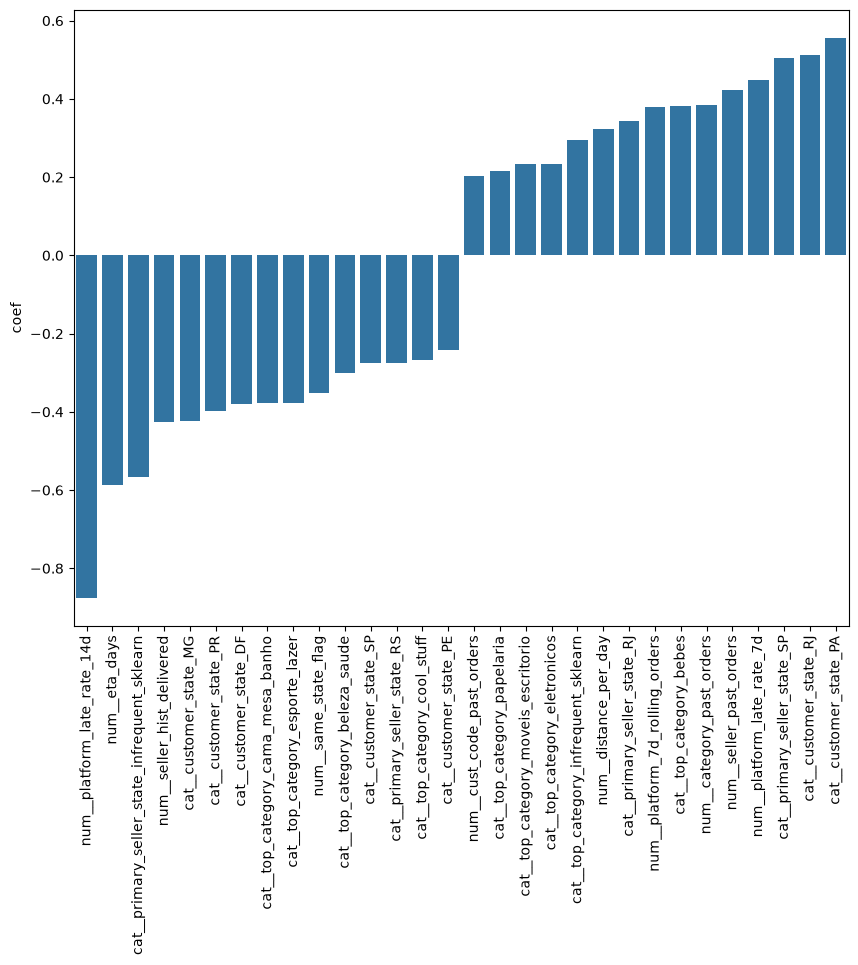

In [83]:
# Bar chart of the coefficients with absolute value above 0.2.
plt.figure(figsize = (10,8))
sns.barplot(coef_df[coef_df.abs() > 0.2].sort_values())
plt.xticks(rotation = 90);

## 10. XGBoost (gradient boosting)

XGBoost reads missing values natively and handles categoricals directly (`enable_categorical=True`), so no imputing, scaling or one-hot is needed.

- `cat_types` fixes the category list from the **training** data, and `astype(cat_types)` applies it to train and test. Categories that appear only in test become missing (this triggers the pandas deprecation warning shown).
- **Search 1** (20 random candidates, same `tscv`, scored by average precision): best mean 0.202 (std 0.103), worst 0.164. The best settings are shown in the two cells after it.
- **Search 2** (30 candidates, more regularised: larger `min_child_weight`, lower learning rate, larger `reg_lambda`) did not beat it (best 0.1996), so I kept the settings from search 1.
- The best-of-50 score is slightly optimistic because the same folds were used to select and to score; I treat 0.20 as an upper estimate.
- `eval_metric="aucpr"` only affects XGBoost's own logging; the selection metric is the scikit-learn `average_precision`.

In [84]:
# Fix the category lists from the training data for XGBoost's categorical support.
# Categories that appear only in test become missing (that is the pandas warning in the output).
cat_types = {c: pd.CategoricalDtype(sorted(X_train[c].dropna().unique())) for c in cat_cols}
Xtr_x = X_train.astype(cat_types)
Xte_x = X_test.astype(cat_types)

C:\Users\saiar\AppData\Local\Temp\ipykernel_16108\1580153104.py:5: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  Xte_x = X_test.astype(cat_types)


In [85]:
# XGBoost search 1: 20 random candidates, 5 time-ordered folds, scored by average precision.
xgb_model = xgb.XGBClassifier(
    tree_method="hist", enable_categorical=True,
    eval_metric="aucpr", n_jobs=-1, random_state=42
)

# search space (the original range comments in this dict are kept as written)
param_dist_xgb = {
    "n_estimators":     randint(100, 600),
    "learning_rate":    loguniform(0.01, 0.2),
    "max_depth":        randint(3, 8),
    "min_child_weight": randint(1, 50),
    "subsample":        uniform(0.6, 0.4),       # 0.6 to 1.0
    "colsample_bytree": uniform(0.5, 0.5),       # 0.5 to 1.0
    "reg_lambda":       loguniform(1e-2, 20)
}

# 20 random candidates x 5 folds = 100 fits; error_score='raise' stops on any fit error instead of hiding it
search_xgb = RandomizedSearchCV(
    xgb_model, param_dist_xgb, n_iter=20, cv=tscv,
    scoring="average_precision", n_jobs=-1, random_state=42,
    error_score="raise", verbose=3
)
search_xgb.fit(Xtr_x, y_train)

# mean and std of the CV score for each candidate
res_xgb = (pd.DataFrame(search_xgb.cv_results_)
             [["mean_test_score", "std_test_score", "params"]]
             .sort_values("mean_test_score", ascending=False))

Fitting 5 folds for each of 20 candidates, totalling 100 fits


In [86]:
# Search 1 results (best candidate at the top).
res_xgb

,mean_test_score,std_test_score,params
3,0.202202,0.103208,"{'colsample_bytree': 0.7159725093210578, 'lear..."
9,0.201569,0.103291,"{'colsample_bytree': 0.9609371175115584, 'lear..."
13,0.201084,0.103360,"{'colsample_bytree': 0.9315517129377968, 'lear..."
10,0.199699,0.103691,"{'colsample_bytree': 0.9143687545759647, 'lear..."
18,0.199464,0.103418,"{'colsample_bytree': 0.9402339195076288, 'lear..."
1,0.198216,0.095163,"{'colsample_bytree': 0.5499874579090014, 'lear..."
11,0.197729,0.099446,"{'colsample_bytree': 0.5078182033705969, 'lear..."
16,0.195204,0.097441,"{'colsample_bytree': 0.5539457134966522, 'lear..."
19,0.194529,0.099713,"{'colsample_bytree': 0.9462794992449889, 'lear..."
6,0.194218,0.094344,"{'colsample_bytree': 0.6154469128110744, 'lear..."


In [87]:
# Parameters of the best candidate of search 1.
res_xgb.iloc[0]['params']

{'colsample_bytree': np.float64(0.7159725093210578),
 'learning_rate': np.float64(0.023927528765580644),
 'max_depth': 5,
 'min_child_weight': 42,
 'n_estimators': 575,
 'reg_lambda': np.float64(16.383103546269133),
 'subsample': np.float64(0.6931085361721216)}

In [88]:
# Parameters of the worst candidate of search 1 (for contrast).
res_xgb.iloc[-1]['params']

{'colsample_bytree': np.float64(0.5325257964926398),
 'learning_rate': np.float64(0.17160445029754812),
 'max_depth': 6,
 'min_child_weight': 14,
 'n_estimators': 341,
 'reg_lambda': np.float64(0.1871851689288996),
 'subsample': np.float64(0.6063865008880857)}

In [89]:
# XGBoost search 2: narrower, more regularised space. It did not beat search 1.
xgb_model2 = xgb.XGBClassifier(
    tree_method="hist", enable_categorical=True,
    eval_metric="aucpr", n_jobs=-1, random_state=42
)

param_dist_xgb2 = {
    "n_estimators":     randint(300, 800),
    "learning_rate":    loguniform(0.01, 0.05),
    "max_depth":        randint(3, 8),
    "min_child_weight": randint(30, 800),
    "subsample":        uniform(0.4, 0.6),       # 0.6 to 1.0
    "colsample_bytree": uniform(0.4, 0.6),       # 0.5 to 1.0
    "reg_lambda":       loguniform(5, 50)
}

search_xgb2 = RandomizedSearchCV(
    xgb_model2, param_dist_xgb2, n_iter=30, cv=tscv,
    scoring="average_precision", n_jobs=-1, random_state=42,
    error_score="raise", verbose=3
)
search_xgb2.fit(Xtr_x, y_train)

res_xgb2 = (pd.DataFrame(search_xgb2.cv_results_)
             [["mean_test_score", "std_test_score", "params"]]
             .sort_values("mean_test_score", ascending=False))

Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [90]:
# Search 2 results.
res_xgb2

,mean_test_score,std_test_score,params
13,0.199610,0.102415,"{'colsample_bytree': 0.7906462153011666, 'lear..."
17,0.199583,0.104218,"{'colsample_bytree': 0.7626504275666903, 'lear..."
0,0.198851,0.105776,"{'colsample_bytree': 0.6247240713084175, 'lear..."
6,0.196325,0.105554,"{'colsample_bytree': 0.5827682615040224, 'lear..."
23,0.177425,0.105136,"{'colsample_bytree': 0.5481256377031607, 'lear..."
1,0.177041,0.103007,"{'colsample_bytree': 0.45998494949080176, 'lea..."
2,0.176274,0.105866,"{'colsample_bytree': 0.9819459112971965, 'lear..."
12,0.163103,0.104924,"{'colsample_bytree': 0.8892768570729005, 'lear..."
21,0.159434,0.103970,"{'colsample_bytree': 0.7064483815465394, 'lear..."
26,0.157275,0.103515,"{'colsample_bytree': 0.8818838538279375, 'lear..."


## 11. Logistic Regression vs XGBoost, fold by fold

`xgb_final` fixes the settings found in search 1. Both models are scored on the **same five folds**; each fold's late rate is also listed because it is the score of a random model (a fold with a 3% late rate cannot reach the AP of a fold with 14%).

| fold | late rate | AP LR | AP XGB | XGB - LR |
|---|---|---|---|---|
| 1 | 0.030 | 0.055 | 0.052 | -0.004 |
| 2 | 0.063 | 0.104 | 0.107 | +0.003 |
| 3 | 0.088 | 0.196 | 0.249 | +0.053 |
| 4 | 0.138 | 0.328 | 0.279 | -0.048 |
| 5 | 0.101 | 0.286 | 0.323 | +0.037 |

- XGBoost wins three folds and loses two, and the differences swing between -0.048 and +0.053, with a mean gap of only about +0.008. This is **within fold-to-fold noise**, so I treat LR and XGBoost as a **tie**.
- I continue with **XGBoost** because it is easier to explain with SHAP and has room to model interactions, not because it scored better.
- Lift (AP divided by the late rate) is 1.7-3.2x across folds: the model ranks late orders better than chance but not by a large factor.

In [91]:
# Compare LR and XGBoost on the same folds: AP per fold, late rate per fold (= score of a random model) and lift.
# XGBoost with the best settings from the first search
xgb_final = xgb.XGBClassifier(
    tree_method="hist", enable_categorical=True, n_jobs=2, random_state=42,
    colsample_bytree=0.716, learning_rate=0.0239, max_depth=5,
    min_child_weight=42, n_estimators=575, reg_lambda=16.38, subsample=0.693,
)

# same folds for both models
# same folds for both models
lr_cv  = cross_validate(lr_final,  X_train, y_train, cv=tscv, scoring="average_precision", n_jobs = -1)
xgb_cv = cross_validate(xgb_final, Xtr_x,   y_train, cv=tscv, scoring="average_precision", n_jobs= -1 )

# late rate of each validation fold = the score of a random model
# late rate of each validation fold = the AP a random model would get
prev = [y_train.iloc[val].mean() for _, val in tscv.split(X_train)]

cmp = pd.DataFrame({
    "fold": range(1, 6),
    "late_rate": prev,
    "AP_lr":  lr_cv["test_score"],
    "AP_xgb": xgb_cv["test_score"],
})
# lift = AP / late rate; xgb_minus_lr = AP difference on that fold
cmp["lift_lr"]  = cmp["AP_lr"]  / cmp["late_rate"]
cmp["lift_xgb"] = cmp["AP_xgb"] / cmp["late_rate"]
cmp["xgb_minus_lr"] = cmp["AP_xgb"] - cmp["AP_lr"]
cmp.round(3)

,fold,late_rate,AP_lr,AP_xgb,lift_lr,lift_xgb,xgb_minus_lr
0,1,0.030,0.055,0.052,1.827,1.699,-0.004
1,2,0.063,0.104,0.107,1.657,1.699,0.003
2,3,0.088,0.196,0.249,2.227,2.836,0.053
3,4,0.138,0.328,0.279,2.369,2.018,-0.048
4,5,0.101,0.286,0.323,2.834,3.197,0.037


## 12. Out-of-fold predictions and choosing a threshold

**Out-of-fold (OOF) predictions.** `oof_predict` fits the model on each fold's training part and predicts the validation part, then stacks them. Every training row ends up with a prediction made by a model that never saw it, in the right time order. These honest predictions are used to pick a decision threshold *without touching the test set*. (The first training block has no OOF prediction because it is never validated.)

- Pooled OOF: **average precision 0.232 vs a late rate of 0.084, lift 2.76x.** This is higher than the fold-mean AP (0.202) because pooling mixes folds with very different late rates; it should not be compared with the per-fold numbers directly.

**Threshold.** I pick the threshold from a **target precision** on the OOF predictions (`pick_by_precision`: the highest-recall threshold that still has at least the target precision).

| target precision | threshold | recall | share of orders flagged |
|---|---|---|---|
| 0.15 | 0.049 | 0.692 | 0.388 |
| 0.20 | 0.080 | 0.506 | 0.213 |
| 0.30 | 0.155 | 0.261 | 0.073 |

Relation: recall = share flagged x precision / late rate. I chose **20% precision** as the operating point. This is an **assumption**, not derived from real costs. I deliberately skipped the cost-based threshold step of the original plan, so there is no cost ratio in this notebook.

Notes on the next cells: `pick_by_precision` is defined first, and the cell with the comment "tie between lr and xgb" comes after it. That cell repeats the OOF computation and prints the same three example targets. (I swapped these two cells so the notebook runs top to bottom; the code itself is unchanged.)

In [92]:
# Out-of-fold (OOF) predictions for the training period: every prediction comes from a model that did not see that row.
# for each fold: fit on its training part, predict its validation part, then stack all predictions
def oof_predict(model, X, y, cv):
    idx, probs = [], []
    for tr, va in cv.split(X):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        probs.append(m.predict_proba(X.iloc[va])[:, 1])
        idx.append(va)
    idx, probs = np.concatenate(idx), np.concatenate(probs)
    return y.iloc[idx].to_numpy(), probs

# OOF labels and predicted probabilities for the validation blocks
y_oof, p_oof = oof_predict(xgb_final, Xtr_x, y_train, tscv)
print("late rate in the validation blocks:", y_oof.mean())

late rate in the validation blocks: 0.08408121480975943


In [93]:
# Pooled OOF average precision compared with the late rate.
ap_pool = average_precision_score(y_oof, p_oof)
base    = y_oof.mean()
print(f"validation PR-AUC {ap_pool:.3f}, late rate {base:.3f}, lift {ap_pool / base:.2f}x")

validation PR-AUC 0.232, late rate 0.084, lift 2.76x


In [94]:
# Pick a threshold from a target precision on the OOF predictions: among thresholds that reach the target
# precision, take the one with the highest recall.
def pick_by_precision(y, p, target):
    # precision/recall at every possible threshold
    prec, rec, thr = precision_recall_curve(y, p)
    # thresholds that reach the target precision
    ok = np.where(prec[:-1] >= target)[0]
    if len(ok) == 0:
        return None                                   # target not reachable
    # among them, the one with the highest recall
    i = ok[np.argmax(rec[:-1][ok])]
    return dict(precision_target=target, threshold=thr[i],
                precision=prec[i], recall=rec[i],
                alerts_share=(p >= thr[i]).mean())

# table of operating points for three target precisions
targets = [0.15, 0.20, 0.30]                          # assumptions: replace with your own
table_a = pd.DataFrame([r for t in targets if (r := pick_by_precision(y_oof, p_oof, t))])
print(table_a.round(3))

   precision_target  threshold  precision  recall  alerts_share
0              0.15      0.049       0.15   0.692         0.388
1              0.20      0.080       0.20   0.506         0.213
2              0.30      0.155       0.30   0.261         0.073


In [95]:
# Repeats the OOF computation of section 12 (same model, same folds, so the same result) and prints the three example
# precision targets using pick_by_precision, which is defined in the cell above (cells 86 and 87 were swapped so the notebook runs top to bottom).
#tie betweeen lr and xgb
y_oof, p_oof = oof_predict(xgb_final, Xtr_x, y_train, tscv)
print("late rate in the validation blocks:", y_oof.mean())

targets = [0.15, 0.20, 0.30]       # examples only
pd.DataFrame([r for t in targets if (r := pick_by_precision(y_oof, p_oof, t))])

late rate in the validation blocks: 0.08408121480975943


,precision_target,threshold,precision,recall,alerts_share
0,0.15,0.048551,0.150002,0.691964,0.387869
1,0.20,0.080413,0.200000,0.505885,0.212677
2,0.30,0.154988,0.300047,0.260958,0.073127


## 13. One evaluation on the test set

The threshold (0.080) chosen on the OOF predictions is applied to the held-out test period with the model refit on all training data. Results:

| | value |
|---|---|
| test late rate | 0.035 |
| PR-AUC (average precision) | 0.047 |
| lift over chance | 1.34x |
| share of orders flagged at threshold 0.080 | 0.456 |
| precision at that threshold | 0.042 |
| recall at that threshold | 0.550 |
| mean predicted probability | 0.120 (actual 0.035) |

**Reading it.** The ranking is only slightly better than chance (lift 1.34x). At the chosen threshold the model flags almost half of the orders and only 4.2% of them are late, far from the 20% precision seen in validation; recall of 55% is mostly the result of flagging so many orders. The average predicted probability (0.120) is about 3.4 times the actual late rate (0.035), so the model is **over-predicting** in this period: probabilities were learned in a period with a much higher late rate (7.7% in train).

**By month (next cell).** The mean prediction is above the actual late rate every month (3.1% vs 0.2%, 7.8% vs 1.2%, 11.2% vs 3.4%, 17.7% vs 6.2%). It rises from June to August along with the actual rate, so the direction is right but the level is too high. Monthly AP is based on very few late orders (May has 639 orders and only about one late order), so the monthly lifts (1.45, 5.40, 1.56, 0.87) are noisy and should not be over-read; August is actually below chance (0.87).

The same cell compares mean feature values between train and test: `platform_7d_rolling_orders` 1,256 -> 1,518 and `eta_days` 25.1 -> 22.0 (shorter promised windows in the test period), so the setting changed between the two periods.

In [96]:
# Single test evaluation: refit on all training data and apply the threshold chosen on the OOF predictions.
thr = table_a.loc[table_a["precision_target"] == 0.20, "threshold"].iloc[0]   # exact value, not the rounded 0.080

# refit XGBoost on all training data
final = clone(xgb_final).fit(Xtr_x, y_train)
p_test = final.predict_proba(Xte_x)[:, 1]          # Xte_x built with X_test.astype(cat_types)

y_t = y_test.to_numpy()
# flag as late when the predicted probability reaches the threshold; tp = correctly flagged late orders
pred = p_test >= thr
tp = (pred & (y_t == 1)).sum()

# test PR-AUC and lift
ap_test = average_precision_score(y_t, p_test)
print(f"test late rate {y_t.mean():.3f} | PR-AUC {ap_test:.3f} | lift {ap_test / y_t.mean():.2f}x")
# alerts_share = share of orders flagged; precision and recall at the chosen threshold
print(f"threshold {thr:.3f} | alerts_share {pred.mean():.3f} | "
      f"precision {tp / max(pred.sum(), 1):.3f} | recall {tp / y_t.sum():.3f}")
print(f"mean predicted prob {p_test.mean():.3f} vs actual test late rate {y_t.mean():.3f}")

test late rate 0.035 | PR-AUC 0.047 | lift 1.34x
threshold 0.080 | alerts_share 0.456 | precision 0.042 | recall 0.550
mean predicted prob 0.120 vs actual test late rate 0.035


In [97]:
# Test results by month, and train vs test means of a few features.
# test predictions with the purchase month
t = test[["order_date"]].copy();
t["y"] = y_t; t["p"] = p_test
t["month"] = pd.to_datetime(t["order_date"]).dt.to_period("M")

# per month: size, actual late rate, mean predicted probability, AP and lift (few late orders in some months)
rows = []
for m, d in t.groupby("month"):
    rows.append(dict(month=m, n=len(d), late_rate=d.y.mean(), mean_pred=d.p.mean(),
                     AP=average_precision_score(d.y, d.p) if d.y.nunique() > 1 else np.nan))
g = pd.DataFrame(rows); 
g["lift"] = g["AP"] / g["late_rate"]; print(g.round(3))

# mean of selected features in train vs test (a rough drift check)
cols = ["platform_7d_rolling_orders", "seller_past_orders", "seller_7d_rolling_orders", "eta_days", "distance_km"]
print(pd.DataFrame({"train_mean": X_train[cols].mean(), "test_mean": X_test[cols].mean()}))

     month     n  late_rate  mean_pred     AP   lift
0  2018-05   639      0.002      0.031  0.002  1.446
1  2018-06  6096      0.012      0.078  0.063  5.401
2  2018-07  6156      0.034      0.112  0.053  1.555
3  2018-08  6351      0.062      0.177  0.054  0.870
                             train_mean    test_mean
platform_7d_rolling_orders  1255.859580  1517.638031
seller_past_orders             3.905479     4.218611
seller_7d_rolling_orders       1.545974     1.361757
eta_days                      25.114315    21.957489
distance_km                  613.210845   570.097869


C:\Users\saiar\AppData\Local\Temp\ipykernel_16108\1468833380.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  g["lift"] = g["AP"] / g["late_rate"]; print(g.round(3))


## 14. Why does it transfer poorly? SHAP and drift

SHAP values (in log-odds) show how much each feature pushes a prediction up or down. I explain the final model on 3,000 test rows and on 3,000 rows sampled from the **last 5,000 training rows** (the most recent training period) and compare the mean SHAP value per feature.

- The bar and beeswarm plots show which features matter most in the test period and in which direction they push.
- The table lists the largest changes in mean SHAP between late-training and test. `platform_late_rate_14d` moves from -0.550 (pushing predictions strongly *down* in recent training) to +0.039 (almost no push) in test, a shift of +0.589. The platform-level time-varying features together (`platform_late_rate_14d`, `platform_delivered_14d`, `platform_delivered_7d`, `platform_7d_rolling_orders`, `platform_late_rate_7d`) account for about 0.955 of the 1.196 total absolute shift in the top 10, roughly **80%** (my arithmetic on the displayed values).

Interpretation (a hypothesis supported by the numbers, not a proven cause): in training the model learned to use the recent platform late rate as a signal about the current regime, but that signal does not carry over to the calmer test months. Features that follow the calendar (`eta_days`, `platform_delivered_7d`) pick up some of the slack. SHAP shows what the model *uses*, not why the world changed.

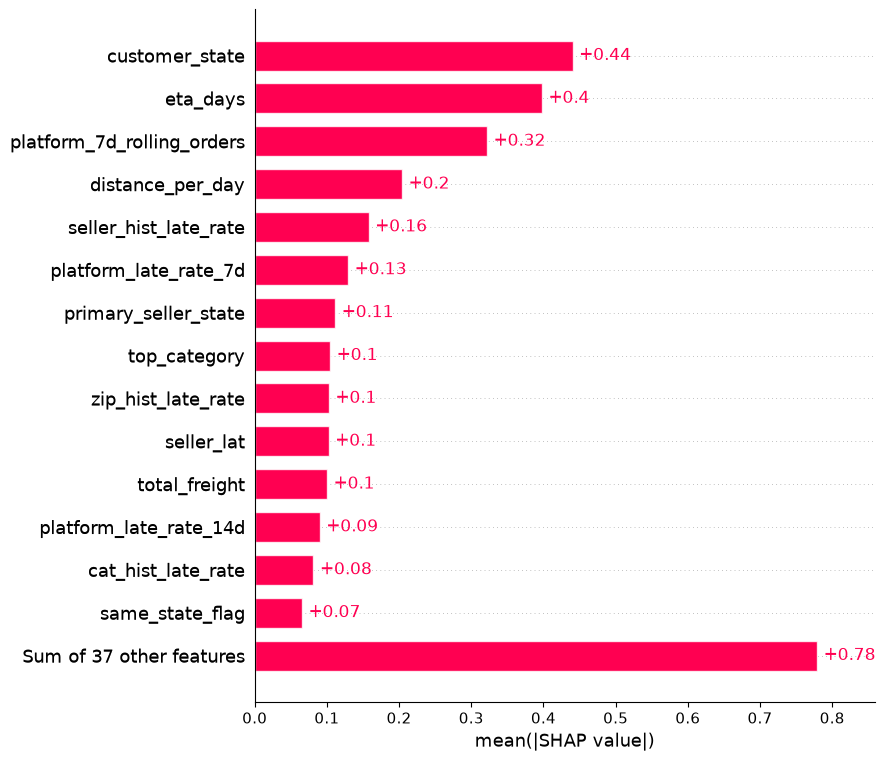

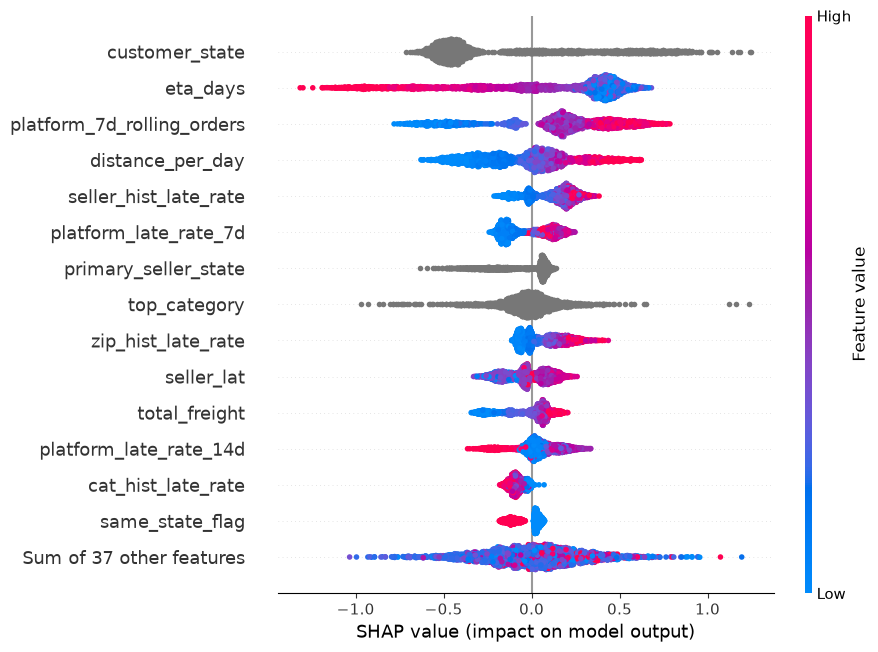

,train_mean_shap,test_mean_shap,diff
platform_late_rate_14d,-0.550,0.039,0.589
platform_delivered_14d,-0.140,-0.000,0.140
eta_days,-0.014,0.096,0.110
platform_delivered_7d,-0.084,0.019,0.103
platform_7d_rolling_orders,0.078,0.164,0.085
distance_per_day,-0.088,-0.038,0.050
state_hist_late_rate,-0.040,-0.001,0.039
platform_late_rate_7d,-0.065,-0.027,0.038
seller_hist_late_rate,0.102,0.129,0.027
zip_hist_late_rate,0.048,0.062,0.015


In [98]:
# SHAP: which features matter in the test period and what changed between late training and test.
# `final` is the XGBoost model fitted on all training data (from the test-set cell)
te_s = Xte_x.sample(3000, random_state=42)                          # test sample
tr_s = Xtr_x.iloc[-5000:].sample(3000, random_state=42)             # recent training rows, for comparison

# SHAP values for both samples
explainer = shap.TreeExplainer(final)
sv_te = explainer(te_s)
sv_tr = explainer(tr_s)

# 1) which features matter most (average absolute effect)
shap.plots.bar(sv_te, max_display=15)

# 2) direction and size of each feature's effect
shap.plots.beeswarm(sv_te, max_display=15)

# 3) what pushes test predictions up compared with late-training predictions?
shift = pd.DataFrame({
    "train_mean_shap": sv_tr.values.mean(axis=0),
    "test_mean_shap":  sv_te.values.mean(axis=0),
}, index=te_s.columns)
shift["diff"] = shift["test_mean_shap"] - shift["train_mean_shap"]
shift.sort_values("diff", key=abs, ascending=False).head(10).round(3)

## 15. Does the recent platform late rate actually track the late rate?

Monthly mean of `platform_late_rate_14d` against the actual monthly late rate (all months, 2017-01 to 2018-08):

- The correlation across the 20 months is only **0.22**, so over this data the feature is a weak and noisy signal about the month's late rate.
- It **lags**: it is built from orders delivered in the previous 14 days, which were bought weeks earlier. In 2017-11 the late rate was 12.4% while the feature read 0.040; it rose to 0.130 in 2018-01 when the late rate had already fallen to 5.7%, and read 0.186 in 2018-04 when the late rate was 4.5%.
- The model likely sees only a handful of spike-and-recovery episodes, so it can learn a pattern (such as "a high recent late rate is followed by recovery") from very few examples. That pattern does not hold in the test months.

In [99]:
# Monthly mean of platform_late_rate_14d vs the actual monthly late rate (and their correlation).
m = (df_order_features.groupby("month")
     .agg(n=("order_id", "size"),
          late_rate=("late_delivery_flag", "mean"),
          plat14=("platform_late_rate_14d", "mean")))
print(m.round(3))
print(m[["late_rate", "plat14"]].corr().iloc[0, 1])

           n  late_rate  plat14
month                          
201701   750      0.029   0.000
201702  1653      0.030   0.000
201703  2546      0.046   0.016
201704  2303      0.066   0.040
201705  3545      0.030   0.052
201706  3135      0.030   0.033
201707  3872      0.028   0.027
201708  4193      0.029   0.022
201709  4150      0.044   0.035
201710  4478      0.042   0.044
201711  7288      0.124   0.040
201712  5513      0.075   0.054
201801  7069      0.057   0.130
201802  6555      0.141   0.046
201803  7003      0.190   0.099
201804  6798      0.045   0.186
201805  6749      0.066   0.080
201806  6096      0.012   0.088
201807  6156      0.034   0.014
201808  6351      0.062   0.045
0.21913937096223415


## 16. Ablation: do the platform features help?

Sections 14-15 suggested that the platform-level, time-varying features may drive the poor transfer to the test period. An **ablation** removes a group of features and re-runs the same evaluation to see what changes. Here: the same XGBoost (`xgb_final`), the same five time-ordered folds (`tscv`), scored by average precision on the training period only (the test set is not used).

Variants: `all`; `no_plat_rate` (drops `platform_late_rate_14d/7d`); `no_plat_vol` (drops `platform_delivered_14d/7d` and `platform_7d_rolling_orders`); `no_plat` (drops all five).

| fold | late rate | all | no_plat_rate | no_plat_vol | no_plat |
|---|---|---|---|---|---|
| 1 | 0.030 | 0.054 | 0.052 | 0.055 | 0.053 |
| 2 | 0.063 | 0.109 | 0.106 | 0.109 | 0.109 |
| 3 | 0.088 | 0.253 | 0.252 | 0.221 | 0.235 |
| 4 | 0.138 | 0.280 | 0.311 | 0.263 | 0.294 |
| 5 | 0.101 | 0.313 | 0.270 | 0.323 | 0.256 |
| mean | | 0.202 | 0.198 | 0.194 | 0.189 |

- `all` has the best mean, but only by 0.004-0.012. The per-fold differences change sign (`no_plat_rate` beats `all` by 0.031 in fold 4 and loses by 0.043 in fold 5) and their spread (std 0.017-0.027, my arithmetic) is larger than the mean gaps. By my rule these are **ties**.
- Re-running the same model moves fold scores by up to about 0.01: the `all` column differs from section 11 for identical settings (fold 5: 0.313 vs 0.323; cause not investigated), which is about the size of the gaps.
- So in cross-validation the platform features are neither clearly helping nor hurting. This cannot show they are harmless in a new regime: the folds contain the spike months and the test period is calm. No variant without them was evaluated on the test set, so the explanation in sections 14-15 stays a hypothesis, and the full-feature model remains the primary (v1) result.

In [103]:
# Does removing the platform metrics help?

plat_rate = ["platform_late_rate_14d", "platform_late_rate_7d"]
plat_vol  = ["platform_delivered_14d", "platform_delivered_7d", "platform_7d_rolling_orders"]

variants = {
    "all":          [],
    "no_plat_rate": plat_rate,
    "no_plat_vol":  plat_vol,
    "no_plat":      plat_rate + plat_vol,
}

res = {}
for name, drop in variants.items():
    cv = cross_validate(clone(xgb_final), Xtr_x.drop(columns=drop), y_train,
                        cv=tscv, scoring="average_precision", n_jobs=5)
    res[name] = cv["test_score"]

abl = pd.DataFrame(res, index=range(1, 6))
abl.insert(0, "late_rate", prev)          # fold late rates from the LR vs XGBoost cell
print(abl.round(3))

print(abl.drop(columns="late_rate").agg(["mean", "std"]).round(3))



   late_rate    all  no_plat_rate  no_plat_vol  no_plat
1      0.030  0.054         0.052        0.055    0.053
2      0.063  0.109         0.106        0.109    0.109
3      0.088  0.253         0.252        0.221    0.235
4      0.138  0.280         0.311        0.263    0.294
5      0.101  0.313         0.270        0.323    0.256
        all  no_plat_rate  no_plat_vol  no_plat
mean  0.202         0.198        0.194    0.189
std   0.114         0.113        0.110    0.103


## 17. Error analysis on the out-of-fold predictions (minimal version)

Uses the out-of-fold (OOF) predictions of the training period (the test set is not used), flagged at `thr` = 0.080. `slice_table` shows, per group, `n`, late orders, `late_rate`, `mean_pred`, share flagged, precision and recall (groups under 200 orders dropped). Only validation blocks have OOF predictions: purchase months 2017-06 to 2018-04.

**By month**
- *Calm months (2017-06 to 2017-10):* late rate 2.8-4.4%, mean prediction 2.3-3.1%, only 0.8-4.3% of orders flagged, recall 1.6-20.3%. The model raises almost no alerts and misses most late orders.
- *Spike months (2017-11, 2018-02, 2018-03):* late rate 12.4%, 14.1%, 19.0% against mean predictions of 7.1%, 7.5%, 8.8%. Under-predicted, but precision (22-31%) and recall (49-63%) are much higher.
- *Right after spikes (2017-12, 2018-01, 2018-04):* 19-41% of orders flagged although the late rate was only 4.5-7.5% (precision 9-13%). This fits the lagging platform late-rate signal of section 15, but it is a hypothesis, not tested.
- Precision follows each month's base rate (mostly 5-10% in calm months, 22-31% in spike months), so a single pooled number hides large differences.

**By promised window (`eta_bin`, five equal-size bins):** the mean prediction is below the actual late rate in every bin, and recall is lowest for the shortest windows (up to 19 days: 0.29, vs 0.50-0.59 elsewhere). The test period has shorter windows on average (22.0 vs 25.1 days), but I have not checked these slices on the test set.

**Missed late orders by month:** the three spike months hold about 56% of the misses but about 64% of all late orders (3,158 of 4,928), so misses are not concentrated there. Calm months (2017-06 to 2017-10) hold about 25% of the misses against about 14% of late orders (672 of 4,928).

**Caveats:** calm months have only 73-187 late orders each; several slices were examined, so only broad patterns should be trusted; the threshold comes from pooled OOF predictions. Slices by state, category, distance, seller history and multi-seller orders were not done.

In [138]:
# Error analysis on the out-of-fold predictions (see the markdown above): by month, by promised-window bin,
# and the share of missed late orders by month.
# validation positions of all 5 folds in time order (same order as y_oof and p_oof)
oof_idx = np.concatenate([va for _, va in tscv.split(X_train)])
oof = X_train.iloc[oof_idx].copy()
oof["y"], oof["p"] = y_oof, p_oof
# flag an order when its predicted probability is at least thr (the 20% precision threshold, 0.080)
oof["pred"] = oof["p"] >= thr
# purchase month of each OOF row
oof["month"] = train.iloc[oof_idx]["month"].values
# five equal-size bins of the promised delivery days
oof["eta_bin"] = pd.qcut(oof["eta_days"], 5, duplicates="drop")

# per-group table: size, late orders, late rate, mean prediction, share flagged, precision, recall
def slice_table(d, col, min_n=200):
    d = d.assign(tp=d["pred"] & (d["y"] == 1))
    g = d.groupby(col, observed=True)
    t = pd.DataFrame({"n": g.size(), "late_n": g["y"].sum(),
                      "late_rate": g["y"].mean(), "mean_pred": g["p"].mean(),
                      "alerts_share": g["pred"].mean(), "tp": g["tp"].sum()})
    t["precision"] = t["tp"] / (t["alerts_share"] * t["n"])
    t["recall"] = t["tp"] / t["late_n"]
    return t[t["n"] >= min_n].drop(columns="tp").round(3)

# by purchase month, then by promised-window bin
print(slice_table(oof, "month"))
print(slice_table(oof, "eta_bin"))

# false negatives = late orders that were not flagged; their share by month
fn = oof[(oof.y == 1) & ~oof.pred]
print((fn.groupby("month").size() / len(fn)).round(3))

           n  late_n  late_rate  mean_pred  alerts_share  precision  recall
month                                                                      
201706  2210      73      0.033      0.026         0.014      0.062   0.027
201707  3872     108      0.028      0.025         0.008      0.097   0.028
201708  4193     122      0.029      0.023         0.009      0.054   0.016
201709  4150     182      0.044      0.029         0.036      0.245   0.203
201710  4478     187      0.042      0.031         0.043      0.083   0.086
201711  7288     904      0.124      0.071         0.270      0.224   0.487
201712  5513     411      0.075      0.086         0.405      0.130   0.708
201801  7069     403      0.057      0.068         0.284      0.094   0.467
201802  6555     926      0.141      0.075         0.297      0.272   0.571
201803  7003    1328      0.190      0.088         0.384      0.312   0.632
201804  6279     284      0.045      0.057         0.188      0.124   0.514
            

## 18. Conclusion

### What was built
A purchase-time-only late-delivery model on 96k delivered Olist orders: point-in-time history features built in SQL (strictly earlier deliveries only, shrunken toward parent rates), a time-based train/test split with a gap, time-ordered cross-validation, a Logistic Regression baseline and a tuned XGBoost model, evaluated with PR-AUC and precision/recall at a stated-assumption threshold.

### What the results say (all numbers are from the outputs above)
- **Hard and unstable problem.** The monthly late rate ranges from about 1% to 19% (about 3% in calm months); train/test late rates are 7.7% and 3.5%; feature correlations with the label are weak (largest 0.115).
- **LR and XGBoost tie in CV** (mean AP 0.194 vs 0.202, fold std about 0.10; XGBoost wins 3 of 5 folds by sign-flipping margins). I keep XGBoost for explainability.
- **Validation vs test.** Pooled OOF: AP 0.232 vs base rate 0.084 (2.76x); at the 20%-precision threshold (0.080) recall is 0.506 with 21.3% of orders flagged. Test: AP 0.047 vs base rate 0.035 (1.34x); the same threshold flags 45.6% of orders with precision 4.2% and recall 55%, and the mean predicted probability is 0.120 against an actual 0.035.
- **Likely driver (hypothesis).** Platform-level, time-varying features, above all `platform_late_rate_14d` (it lags the real late rate; monthly correlation 0.22), account for about 80% of the top-10 SHAP shift between late training and test. The ablation (section 16) shows no clear benefit or harm in CV (mean AP change -0.004 to -0.012, within noise), so CV can neither confirm nor rule out this explanation, and no variant without them was tested on the test set.
- **Where it errs (OOF, section 18).** Almost no alerts in calm months, under-prediction of the biggest spikes, many alerts right after spikes, and the lowest recall for the shortest promised windows (0.29 vs 0.50-0.59).

### Limitations
- Only about 20 usable months (2017-01 to 2018-08) with a few spike episodes, so the model has very few independent examples of how platform-wide conditions behave. Results are strongly period dependent.
- One test window (roughly May-Aug 2018), calmer than training; its monthly metrics rest on very few late orders.
- The XGBoost search and the model comparison use the same folds (best-of-50 selection), and the shrinkage strength `K_PRIOR = 20` was not tuned by CV.
- The 20% target precision is an assumption; there is no cost-based threshold.
- The label is relative to the platform's *estimated* date, and the promised window itself changed over time (`eta_days` 25.1 in train vs 22.0 in test), so "late" is not the same thing as slow transit.
- Multi-seller orders (about 1,278) are assigned to the highest-priced item's seller; 476 orders (0.5%) have no distance; the geolocation is a zip-prefix median.